# Evaluation: five test sets, the follow up runs, final tables and figures

**Where we are.** Stage B rejected the hypothesis: Soft-SAAS is never better than SAAS, and both cut searches from 3 to 1 with no HotpotQA cost against plain continuation. No policy learned *when* to search: each settled on a fixed search count, because the starting policy almost never tries answering without a search, so a reward for knowing when not to search has nothing to act on.

**What this notebook does**
1. Writes the code, runs the unit tests (33), starts the search server.
2. Writes the three out of domain test sets from the FlashRAG copies: 2WikiMultihopQA (1,000), MuSiQue (500), PopQA (500), and prints how their metadata parsed.
3. Dry run: the agent on 5 questions of each new set, and 2 training steps with forced answers.
4. Reference points on the new sets (no search, one search with the question as the query, the prompted agent) for the base model and the stage A2 policy, plus K = 8 closed book samples on all five sets for p(q) (for QOR and the adaptivity check).
5. The ten stage B policies on the three new sets (about 7 minutes each).
6. Ten follow up runs of 100 steps from the same stage A2 policy, each evaluated on all five sets:

| Runs | Why |
|---|---|
| `B_plain_s1`, `B_plain_s2` | Seed matched controls, so every SAAS and Soft-SAAS seed has its own plain baseline |
| `B_saas_fa_s0`, `B_soft_fa_s0`, `B_plain_fa_s0` | **The main new experiment.** 2 of the 8 rollouts per question must answer without searching, and this time the policy cannot dodge it (see below). Does a boundary reward then teach *when* to search? Plain with the same forcing is the control |
| `B_saas_own_s0` | SAAS with SAAS's own definition of N_min. Tests whether our change to N_min mattered |
| `B_saas_fa_s1..2`, `B_soft_fa_s1..2` | Seeds for the forced answer runs |

7. Prints one JSON (also saved as `outputs/final_summary.json`), two figures, and 20 out of domain sample questions.

**Forcing that cannot be dodged.** In stage A2 the policy escaped the forced rollouts by never closing its `<think>` block, which is what the forcing waited for. Now a forced rollout also stops when it opens `<search>`; the environment cuts that tag off and writes `</think>` and `<answer>` instead (masked from the loss). The two forced rollouts make no search and are never charged; the other six decide for themselves. Evaluation never forces.

**Pasting early.** The results cell works with whatever has finished. A good moment is after `B_plain_fa_s0` (about 7 hours in): that covers everything except the extra seeds and the N_min check.

**What the results answer**
* Soft-SAAS against SAAS on all five sets, per seed and averaged over seeds, and the proposal's success rule on the multi hop sets.
* Each penalty against plain continuation with the same seed, and against one search with the question as the query.
* Question level over search (QOR), the search rate on questions the policy could not answer closed book, step level over search (SOR) and redundant searches.
* Whether forced exploration plus a boundary reward produces a policy whose search rate depends on the question.

In [ ]:
!pip install -q "trl[vllm,peft]==1.16.0"
!pip uninstall -y -q torchao  # Colab ships 0.10, peft refuses to build LoRA layers next to it; nothing here uses it

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.3.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.


## Storage


In [ ]:
PROJECT_NAME = "search_or_think"
HF_REPO = ""    # e.g. "kshitijsahu/search_or_think", a PRIVATE dataset repo. Used only when Drive does not mount.
HF_TOKEN = ""   # write token from huggingface.co/settings/tokens

import os
import shutil
import sys

CODE = "/content/code"  # code is written fresh by this notebook, so it never has to survive a session
os.makedirs(f"{CODE}/sot", exist_ok=True)
sys.path.insert(0, CODE)

try:
    from google.colab import drive
    drive.mount("/content/drive", timeout_ms=90_000)
    PROJECT, STORE = f"/content/drive/MyDrive/{PROJECT_NAME}", "drive"
except Exception as e:  # the credential propagation bug, or no Drive at all
    print("Drive did not mount:", type(e).__name__, str(e)[:150])
    PROJECT, STORE = "/content/work", "local"

DATA, OUT, CKPT = f"{PROJECT}/data", f"{PROJECT}/outputs", f"{PROJECT}/checkpoints"
RUN = f"{CKPT}/grpo_Qwen2.5-0.5B-Instruct_"  # a run's folder is RUN + its tag
RUN_A = RUN + "stageA2"                       # the branch point of every stage B run
SAVE_IDX = 1 if STORE == "drive" else 0
for d in (DATA, OUT, CKPT):
    os.makedirs(d, exist_ok=True)

STAGE_B = ["B_plain_s0", "B_fixed02_s0", "B_fixed05_s0", "B_fixed10_s0", "B_saas_s0", "B_saas_s1", "B_saas_s2", "B_soft_s0", "B_soft_s1", "B_soft_s2"]
# Every follow up run starts like the stage B runs: same weights, data, boundary file and optimiser settings.
# shortcut: no checkpoints during a run (--save_steps above --steps); a run cut off by a dead session starts over.
B = (f"--project {PROJECT} --init_checkpoint {RUN_A}/final --train_file {DATA}/train_stageB.jsonl "
     f"--boundary {DATA}/boundary_stageB.jsonl --online_nmin --warmup off --lr 3e-6 --steps 100 --save_steps 1000")
INF = f"--project {PROJECT} --n 1000 --n_nq 500"
OOD = "2wiki,musique,popqa"
ALL5 = "hotpotqa,nq,2wiki,musique,popqa"


def _api():
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN or None)
    api.create_repo(HF_REPO, repo_type="dataset", private=True, exist_ok=True)
    return api


def pull():
    """data/, outputs/ and the final policies down from the Hugging Face repo."""
    from huggingface_hub import snapshot_download
    snapshot_download(HF_REPO, repo_type="dataset", token=HF_TOKEN or None, local_dir=PROJECT,
                      allow_patterns=["data/*", "outputs/*", "outputs/*/*", "checkpoints/*/final/*"])
    print("pulled data/, outputs/ and the final policies from", HF_REPO)


def push(*subdirs):
    """Folders under PROJECT up to the Hugging Face repo. Does nothing in drive mode."""
    if STORE != "local" or not HF_REPO:
        return
    api = _api()
    for s in subdirs:
        if os.path.isdir(f"{PROJECT}/{s}"):
            api.upload_folder(folder_path=f"{PROJECT}/{s}", path_in_repo=s, repo_id=HF_REPO, repo_type="dataset")
            print("pushed", s)


def push_runs(tags):
    """Each finished run's final policy and logs. Does nothing in drive mode."""
    if STORE != "local" or not HF_REPO:
        return
    api = _api()
    for t in tags:
        if os.path.isdir(f"{RUN}{t}/final"):
            api.upload_folder(folder_path=f"{RUN}{t}", path_in_repo=f"checkpoints/{os.path.basename(RUN)}{t}",
                              repo_id=HF_REPO, repo_type="dataset", ignore_patterns=["checkpoint-*/*"])
            print("pushed", t)


if STORE == "local" and HF_REPO and not os.path.exists(f"{DATA}/boundary_stageB.jsonl"):
    pull()

import torch, trl, vllm
GPU = torch.cuda.get_device_name(0)
print(f"store={STORE} project={PROJECT}")
print("trl", trl.__version__, "| vllm", vllm.__version__, "| GPU", GPU,
      f"| free: {shutil.disk_usage(PROJECT).free / 1e9:.0f} GB")

NEEDED = {f"{RUN_A}/final/config.json": "the stage A2 policy",
          f"{DATA}/train_stageB.jsonl": "the stage B training set",
          f"{DATA}/boundary_stageB.jsonl": "the stage B boundary file",
          f"{OUT}/stageA2/closed_pool.jsonl": "closed book samples of the stage A2 policy",
          f"{OUT}/stageA2_relabel/agent_train.jsonl": "the stage A2 policy's own rollouts on the training set",
          f"{OUT}/stageA2/rag.jsonl": "the stage A2 reference rows",
          f"{OUT}/base_0.5B/rag.jsonl": "the base model reference rows"}
NEEDED.update({f"{RUN}{t}/final/config.json": f"the stage B policy {t}" for t in STAGE_B})
NEEDED.update({f"{OUT}/{t}/agent.jsonl": f"the stage B test rows of {t}" for t in STAGE_B})
MISSING = {p: why for p, why in NEEDED.items() if not os.path.exists(p)}
assert not MISSING, ("missing:\n" + "\n".join(f"  {p}  ({w})" for p, w in MISSING.items())
                     + f"\nstore={STORE}. In drive mode, check that the mount landed on the right account."
                     + " In local mode, set HF_REPO and HF_TOKEN above and rerun this cell.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
store=drive project=/content/drive/MyDrive/search_or_think
trl 1.16.0 | vllm 0.31.0 | GPU NVIDIA L4 | free: 233 GB


## Code
Every file in full, written to `/content/code`.

| File | Change since stage B |
|---|---|
| `sot/rollout.py` | `strict` forcing: a forced rollout that opens the other action is cut back and given the forced tag |
| `train_grpo.py` | `--force_strict` |
| `sot/data.py` | `prepare_ood`: 2WikiMultihopQA, MuSiQue and PopQA from the FlashRAG copies, read line by line |
| `run_inference.py` | `--datasets`, `--n_ood`, task `closed_test` (K closed book samples on test sets) |
| `sot/analysis.py` | SOR uses supporting titles on any set that has them and reports how often evidence was complete; QOR adds the search rate on the other questions and F1 on the known ones; `seed_averaged_paired` |
| `test_sot.py` | 33 tests |
| the rest | unchanged |

In [2]:
%%writefile /content/code/sot/__init__.py
"""Search or Think? project package."""

Writing /content/code/sot/__init__.py


In [3]:
%%writefile /content/code/sot/scoring.py
"""Answer scoring (SQuAD / HotpotQA style EM and F1) and evidence matching."""
import collections
import re
import string
import unicodedata

_PUNCT = set(string.punctuation)


def normalize_answer(s):
    s = unicodedata.normalize("NFKC", s or "").lower()
    s = "".join(ch for ch in s if ch not in _PUNCT)
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())


def em(pred, golds):
    p = normalize_answer(pred)
    return float(any(p == normalize_answer(g) for g in golds))


def f1(pred, golds):
    p = normalize_answer(pred)
    best = 0.0
    for g in golds:
        g = normalize_answer(g)
        # HotpotQA official eval: yes/no answers only score on an exact match
        if p != g and ({p, g} & {"yes", "no", "noanswer"}):
            continue
        common = collections.Counter(p.split()) & collections.Counter(g.split())
        ns = sum(common.values())
        if ns:
            prec, rec = ns / len(p.split()), ns / len(g.split())
            best = max(best, 2 * prec * rec / (prec + rec))
    return best


def has_answer(text, golds):
    t = f" {normalize_answer(text)} "
    return any(f" {normalize_answer(g)} " in t for g in golds if normalize_answer(g))


def norm_title(t):
    return unicodedata.normalize("NFKC", t or "").strip().strip('"').lower()


def norm_query(q):
    """Two queries that differ only in case or spacing are the same query: BM25 returns the same passages."""
    return " ".join((q or "").lower().split())


def n_distinct(queries):
    """Distinct queries in one episode. A repeated query retrieves nothing new, so this is how many retrievals
    the episode really used; N_min is estimated from it (see analysis.boundary_table)."""
    return len({norm_query(q) for q in queries})


def knows(answer, golds):
    """The correctness test behind p(q): cover match, i.e. a gold answer is contained in the closed book answer.
    Lenient on form because p(q) measures knowledge, and strict EM misses verbose correct answers (interim report)."""
    return has_answer(answer or "", golds)

Writing /content/code/sot/scoring.py


In [4]:
%%writefile /content/code/sot/data.py
"""HotpotQA (distractor) and NQ-open loaders from the Hugging Face Hub, as flat question records, and the out of
domain test sets (2WikiMultihopQA, MuSiQue, PopQA) from the FlashRAG copies."""
import json
import random

FLASHRAG = "RUC-NLPIR/FlashRAG_datasets"
# short name -> (file in the FlashRAG repo, questions kept). Dev sets as test, as for HotpotQA; PopQA has only test.
OOD = {"2wiki": ("2wikimultihopqa/dev.jsonl", 1000), "musique": ("musique/dev.jsonl", 500),
       "popqa": ("popqa/test.jsonl", 500)}


def _first_ok(*loaders):
    err = None
    for load in loaders:
        try:
            return load()
        except Exception as e:  # dataset ids move around on the Hub; try the fallback id
            err = e
            print("falling back after:", repr(e)[:150])
    raise err


def load_split(name, split):
    from datasets import load_dataset
    if name == "hotpotqa":
        return _first_ok(lambda: load_dataset("hotpotqa/hotpot_qa", "distractor", split=split),
                         lambda: load_dataset("hotpot_qa", "distractor", split=split, trust_remote_code=True))
    return _first_ok(lambda: load_dataset("google-research-datasets/nq_open", split=split),
                     lambda: load_dataset("nq_open", split=split))


def sup_titles(meta):
    """Supporting page titles from a FlashRAG metadata dict, whichever layout it uses: supporting_facts as
    {"title": [...]} or as [[title, sent], ...] (2Wiki), or paragraphs with is_supporting (MuSiQue). [] if none."""
    if not isinstance(meta, dict):
        return []
    sf = meta.get("supporting_facts")
    if isinstance(sf, dict) and isinstance(sf.get("title"), list):
        return sorted({str(t) for t in sf["title"]})
    if isinstance(sf, list):
        titles = {f[0] if isinstance(f, (list, tuple)) and f else f.get("title") if isinstance(f, dict) else None
                  for f in sf}
        return sorted(str(t) for t in titles if t)
    paras = meta.get("paragraphs")
    if isinstance(paras, list):
        return sorted({str(p["title"]) for p in paras if isinstance(p, dict) and p.get("is_supporting") and p.get("title")})
    return []


def flashrag_record(name, i, x):
    golds = x.get("golden_answers") or x.get("answers") or ([x["answer"]] if x.get("answer") else [])
    golds = [golds] if isinstance(golds, str) else golds
    return {"id": f"{name}_{x.get('id', i)}", "dataset": name, "split": "test", "question": x["question"],
            "golds": [str(g) for g in golds if str(g).strip()], "sup_titles": sup_titles(x.get("metadata"))}


def prepare_ood(data_dir, seed=42):
    """Writes data/<name>_test.jsonl for each out of domain set: a fixed random sample of the FlashRAG file, read
    line by line (its metadata varies between rows, which Arrow schema inference can choke on). Returns a report:
    pool size, questions kept, share with supporting titles, and the metadata keys seen, to check the parsing."""
    from huggingface_hub import hf_hub_download
    report = {}
    for name, (path, n) in OOD.items():
        with open(hf_hub_download(FLASHRAG, path, repo_type="dataset")) as f:
            raw = [json.loads(line) for line in f if line.strip()]
        recs = [flashrag_record(name, i, x) for i, x in enumerate(raw) if x.get("question")]
        recs = [r for r in recs if r["golds"]]
        pick = sorted(random.Random(seed).sample(range(len(recs)), n))
        keep = [recs[i] for i in pick]
        assert len({r["id"] for r in keep}) == n, f"{name}: ids are not unique"
        with open(f"{data_dir}/{name}_test.jsonl", "w") as f:
            f.writelines(json.dumps(r) + "\n" for r in keep)
        meta = next((x.get("metadata") for x in raw if isinstance(x.get("metadata"), dict)), {}) or {}
        report[name] = {"pool": len(recs), "n": n, "with_sup_titles": sum(bool(r["sup_titles"]) for r in keep) / n,
                        "metadata_keys": sorted(meta)[:20], "example": {k: keep[0][k] for k in ("id", "question", "golds",
                                                                                                "sup_titles")}}
    return report


def to_record(name, hf_split, out_split, i, x):
    """Same ids and fields as the original data prep cell, so records from different runs match."""
    if name == "hotpotqa":
        return {"id": x["id"], "dataset": name, "split": out_split, "question": x["question"],
                "golds": [x["answer"]], "sup_titles": sorted(set(x["supporting_facts"]["title"])),
                "type": x["type"], "level": x["level"]}
    return {"id": f"nq_{hf_split}_{i}", "dataset": name, "split": out_split, "question": x["question"],
            "golds": list(x["answer"]), "sup_titles": []}

Writing /content/code/sot/data.py


In [5]:
%%writefile /content/code/sot/retrieval.py
"""Client for the local BM25 retrieval server (retriever_server.py)."""
import requests


class Retriever:
    def __init__(self, url="http://127.0.0.1:8000", k=3, batch=200, timeout=900):
        self.url, self.k, self.batch, self.timeout = url, k, batch, timeout

    def health(self):
        return requests.get(f"{self.url}/health", timeout=10).json()

    def __call__(self, queries):
        out = []
        for i in range(0, len(queries), self.batch):
            r = requests.post(f"{self.url}/search", json={"queries": queries[i:i + self.batch], "k": self.k},
                              timeout=self.timeout)
            r.raise_for_status()
            out += r.json()["results"]
        return out

Writing /content/code/sot/retrieval.py


In [6]:
%%writefile /content/code/sot/agent.py
"""Prompts and the batched multi turn search agent loop (model and retriever passed in as callables)."""
import re

SEARCH_RE = re.compile(r"<search>(.*?)</search>", re.S)
ANSWER_RE = re.compile(r"<answer>((?:(?!<answer>).)*?)</answer>", re.S)  # innermost, if a prefill <answer> is repeated
LIMIT_MSG = "\n\n<info>\nSearch limit reached. Give your final answer now.\n</info>\n\n"
# "<info>" is a stop string: only the environment may write search results. A model that opens its own <info> ends
# the episode there (stop_reason "fake_info"), scored on whatever answer it has, which is normally none.
STOP = ["</search>", "</answer>", "<info>"]

_ANSWER_FMT = ("give the final answer inside <answer> and </answer> using only a few words, "
               "for example <answer> Paris </answer>.")
_DIRECT_FMT = "Respond with only the final answer in a few words inside <answer> and </answer>, with no explanation."

_AGENT_EXAMPLE = ("Example:\nQuestion: What is the capital of the country where the Eiffel Tower is?\n"
                  "<think> I need to know which country the Eiffel Tower is in. </think>\n"
                  "<search> Eiffel Tower location </search>\n\n"
                  "<info>\nDoc 1 (Title: Eiffel Tower) The Eiffel Tower is a wrought-iron lattice tower in Paris, France.\n</info>\n\n"
                  "<think> The tower is in France, and the capital of France is Paris. </think>\n"
                  "<answer> Paris </answer>")


def agent_instruction(question, max_searches=4):
    return ("Answer the question below. Reason inside <think> and </think> every time you get new information. "
            "If you lack some knowledge, search Wikipedia by writing <search> your query </search>, and the top "
            "results will be returned between <info> and </info>. Never invent search results. You can search up to "
            f"{max_searches} times. When you are ready, {_ANSWER_FMT}\n\n{_AGENT_EXAMPLE}\n\nQuestion: {question}")


def closed_book_instruction(question):
    return f"Answer the question below from your own knowledge. {_DIRECT_FMT}\n\nQuestion: {question}"


def rag_instruction(question):
    return ("Answer the question below. Wikipedia search results are provided between <info> and </info>. "
            f"{_DIRECT_FMT}\n\nQuestion: {question}")


def format_info(passages):
    body = "\n".join(f"Doc {i + 1} (Title: {p.get('title', '')}) {p.get('text', '')}" for i, p in enumerate(passages))
    return f"\n\n<info>\n{body or 'No results.'}\n</info>\n\n"


def extract_answer(text, lenient=False):
    m = ANSWER_RE.findall(text)
    if m:
        return m[-1].strip()
    if not lenient:
        return None
    if "<answer>" in text:  # answer opened (e.g. by the prefill) but never closed: keep its first line
        return " ".join(text.rsplit("<answer>", 1)[1].strip().split("\n")[0].split()[:12])
    # fallback for small models that skip the tags: last line outside think/info blocks, capped at 12 words
    t = re.sub(r"<info>.*?</info>|<think>.*?</think>", " ", text, flags=re.S)
    t = re.sub(r"<[^>]+>", " ", t)
    lines = [ln.strip() for ln in t.splitlines() if ln.strip()]
    return " ".join(lines[-1].split()[:12]) if lines else ""


def run_agent(generate, retrieve, prompts, *, allow_search=True, max_searches=4, max_turn_tokens=512,
              temperature=0.0, prefill=None):
    """generate(prompts, stop, max_tokens, temperature) -> list[str]; outputs include the stop string.
    retrieve(queries) -> list[list[{title, text}]].
    prefill: optional list of {"text", "searches"} placed at the start of the assistant turn (forced RAG search).
    Returns one state dict per prompt with text, searches, answer, format_ok, n_search, stop_reason."""
    states = [{"prompt": p, "text": prefill[i]["text"] if prefill else "",
               "searches": list(prefill[i]["searches"]) if prefill else [],
               "done": False, "over_limit": 0, "stop_reason": None}
              for i, p in enumerate(prompts)]
    stop = STOP if allow_search else ["</answer>"]
    for _ in range(max_searches + 2 if allow_search else 1):
        active = [s for s in states if not s["done"]]
        if not active:
            break
        outs = generate([s["prompt"] + s["text"] for s in active], stop, max_turn_tokens, temperature)
        need, queries = [], []
        for s, out in zip(active, outs):
            s["text"] += out
            tail = out.rstrip()
            if tail.endswith("</answer>"):
                s["done"], s["stop_reason"] = True, "answer"
            elif allow_search and tail.endswith("</search>"):
                if len(s["searches"]) >= max_searches:
                    s["over_limit"] += 1
                    if s["over_limit"] >= 2:
                        s["done"], s["stop_reason"] = True, "search_limit"
                    else:
                        s["text"] += LIMIT_MSG
                else:
                    m = SEARCH_RE.findall(out)
                    need.append(s)
                    queries.append(m[-1].strip() if m else "")
            elif allow_search and tail.endswith("<info>"):
                s["done"], s["stop_reason"] = True, "fake_info"
            else:
                s["done"], s["stop_reason"] = True, "no_tag" if out else "too_long"
        if queries:
            for s, q, res in zip(need, queries, retrieve(queries)):
                s["searches"].append({"query": q, "passages": res})
                s["text"] += format_info(res)
    for s in states:
        if not s["done"]:
            s["stop_reason"] = "max_turns"
        s["answer"] = extract_answer(s["text"], lenient=True)
        s["format_ok"] = extract_answer(s["text"]) is not None
        s["n_search"] = len(s["searches"])
    return states

Writing /content/code/sot/agent.py


In [7]:
%%writefile /content/code/sot/rewards.py
"""Rewards: plain GRPO, fixed per search penalty, SAAS, and Soft-SAAS (Eq. 1 of the proposal).

One definition per quantity, used in training, relabelling and analysis alike:
  p(q)   share of the K search disabled rollouts whose answer covers a gold answer (scoring.knows, cover match)
  N_min  fewest searches among search enabled rollouts with F1 = 1 on the answer inside <answer> tags (is_correct)
  gate   a search penalty applies only to rollouts with F1 = 1 on the answer inside <answer> tags (is_correct)
SAAS and Soft-SAAS read the same p(q) and N_min, so the hard vs soft boundary is the only difference between them.
The released SAAS code uses EM for its labels; we keep cover match for p(q) and store an EM based p(q) next to it.
"""
from dataclasses import dataclass
from typing import Optional

MAX_SEARCHES = 4
ALPHA = 0.05  # SAAS: alpha in the paper (App. B.1), beta = 0.05 in search/utils.py of the released code

# NoSearch needs delta of K search disabled rollouts correct. SAAS uses delta = 2 of 4 in the paper (Sec. 3.1) and in
# the released code (head_correct_count >= 2 with disable_search_first_n = 4); as a ratio it carries over to K = 8.
NOSEARCH_MIN_P = 0.5
# The paper and the released code disagree on NeedSearch. Paper: no search disabled rollout is correct and some
# search enabled one is. Code (generate_with_search.py, mq_group_reward_func): fewer than delta are correct and some
# search enabled one is. We follow the code by default; "paper" stays available for the comparison.
SAAS_RULE = "code"


def is_correct(f1):
    return f1 >= 1.0 - 1e-9


@dataclass
class Boundary:
    p: float              # p(q)
    n_min: Optional[int]  # N_min (None if no search enabled rollout was correct)
    label: str            # SAAS label: NoSearch / NeedSearch / Undetermined


def saas_label(p, n_min, rule=SAAS_RULE, nosearch_min_p=NOSEARCH_MIN_P):
    if rule not in ("code", "paper"):
        raise ValueError(f"unknown SAAS rule {rule!r}")
    if p >= nosearch_min_p:
        return "NoSearch"
    if n_min is not None and (rule == "code" or p == 0):
        return "NeedSearch"
    return "Undetermined"


def estimate_boundary(disabled_correct, enabled_rollouts, rule=SAAS_RULE, nosearch_min_p=NOSEARCH_MIN_P):
    """disabled_correct: list[bool] (cover match); enabled_rollouts: list of (correct: bool, n_search: int) (F1 = 1)."""
    p = sum(disabled_correct) / len(disabled_correct) if disabled_correct else 0.0
    ns = [n for c, n in enabled_rollouts if c]
    n_min = min(ns) if ns else None
    return Boundary(p, n_min, saas_label(p, n_min, rule, nosearch_min_p))


def penalty_saas(n_search, b):
    if b.label == "NoSearch":
        return float(n_search)
    if b.label == "NeedSearch":
        return float(max(0, n_search - b.n_min))
    return 0.0  # Undetermined questions get no search signal


def penalty_soft(n_search, b, max_searches=MAX_SEARCHES):
    n_min = max_searches if b.n_min is None else b.n_min
    return b.p * n_search + (1 - b.p) * max(0, n_search - n_min)


def reward_plain(f1, n_search):
    return f1


def reward_fixed(f1, n_search, lam):
    return f1 - lam * n_search


def reward_saas(f1, n_search, b, alpha, w=1.0):
    return f1 - (alpha * w * penalty_saas(n_search, b) if is_correct(f1) else 0.0)


def reward_soft_saas(f1, n_search, b, alpha, w=1.0, max_searches=MAX_SEARCHES):
    return f1 - (alpha * w * penalty_soft(n_search, b, max_searches) if is_correct(f1) else 0.0)


def compute_rewards(kind, f1s, n_searches, boundaries, *, lam=0.1, alpha=ALPHA, w=1.0, format_bonus=0.0,
                    format_ok=None):
    """Rewards for a batch of rollouts. Returns (rewards, penalised), penalised[i] = rollout i lost reward for searching.
    format_bonus: reward for a well formed but wrong answer (F1 = 0), as in the released SAAS code (0.1 there)."""
    rewards, penalised = [], []
    for i, (f, n) in enumerate(zip(f1s, n_searches)):
        if kind == "plain":
            pen = 0.0
        elif kind == "fixed":
            pen = lam * w * n
        elif kind == "saas":
            pen = alpha * w * penalty_saas(n, boundaries[i]) if is_correct(f) else 0.0
        elif kind == "soft":
            pen = alpha * w * penalty_soft(n, boundaries[i]) if is_correct(f) else 0.0
        else:
            raise ValueError(f"unknown reward {kind!r}")
        bonus = format_bonus if format_bonus and f == 0 and format_ok is not None and format_ok[i] else 0.0
        rewards.append(f + bonus - pen)
        penalised.append(pen > 0)
    return rewards, penalised


def tighten_n_min(boundaries, f1s, n_searches, G, rule=SAAS_RULE):
    """On-policy N_min, as in the released SAAS code: within each group of G rollouts of one question, N_min is at
    most the fewest searches of the group's own correct rollouts. p(q) is left as it was measured."""
    out = list(boundaries)
    for g in range(0, len(out), G):
        ns = [n for f, n in zip(f1s[g:g + G], n_searches[g:g + G]) if is_correct(f)]
        if not ns:
            continue
        for i in range(g, min(g + G, len(out))):
            b = out[i]
            n_min = min(ns) if b.n_min is None else min(b.n_min, min(ns))
            out[i] = Boundary(b.p, n_min, saas_label(b.p, n_min, rule))
    return out


def group_stats(rewards, G):
    """Share of question groups (G consecutive rollouts) with no reward variance, which give GRPO no gradient."""
    groups = [rewards[g:g + G] for g in range(0, len(rewards), G)]
    flat = [max(x) - min(x) < 1e-8 for x in groups]
    n = max(len(groups), 1)
    return {"zero_var_share": sum(flat) / n,
            "zero_var_all_zero": sum(f and abs(x[0]) < 1e-8 for f, x in zip(flat, groups)) / n,
            "flat_groups": [i for i, f in enumerate(flat) if f]}


class WarmupTrigger:
    """Self triggered warm up: w(t) = 0 until the moving average of training reward improves by
    less than eps over `window` steps, then w rises linearly to 1 over `ramp` steps.

    Defaults: a 20 step mean that gains less than 0.01 over 40 steps. The interim report's rule (10 step mean,
    under 0.005 over 20 steps) is below the noise of 64 rollouts per step and fires while reward still rises: it
    did so at step 36 of a stage 0 sweep run. OLD_TRIGGER keeps it for the comparison in the report."""

    def __init__(self, window=40, eps=0.01, ramp=50, ma=20):
        self.window, self.eps, self.ramp, self.ma = window, eps, ramp, ma
        self.rewards, self.mas, self.trigger_step = [], [], None

    def update(self, reward_mean):
        self.rewards.append(reward_mean)
        recent = self.rewards[-self.ma:]
        self.mas.append(sum(recent) / len(recent))
        t = len(self.rewards) - 1
        if self.trigger_step is None and len(self.mas) > self.window + self.ma:
            if self.mas[-1] - self.mas[-1 - self.window] < self.eps:
                self.trigger_step = t
        return self.weight(t)

    def weight(self, t):
        if self.trigger_step is None:
            return 0.0
        return max(0.0, min(1.0, (t - self.trigger_step) / self.ramp))


OLD_TRIGGER = dict(window=20, eps=0.005, ma=10)


def replay_trigger(rewards, **kw):
    """Step (1-based, as in log.jsonl) after which the trigger fires on a logged reward curve, or None."""
    t = WarmupTrigger(**kw)
    for r in rewards:
        t.update(r)
    return None if t.trigger_step is None else t.trigger_step + 1


class Warmup:
    """w(t) per optimizer step, keyed by the trainer's global_step.

    spec  "off"            w = 1 from the first step (the penalty is simply on, e.g. a run branched at the switch)
          "manual_step:N"  w = 0 before step N, then a linear ramp to 1 over `ramp` steps (ramp 0 = SAAS's hard switch)
          "self"           WarmupTrigger on the training reward
    observe() may be called many times within one optimizer step (reward calls, accumulation micro-batches,
    resampling); a step's mean reward is committed to the trigger exactly once, when a later step asks for its weight.
    The trigger is tracked for every spec, so any run's log shows when the self trigger would have fired."""

    def __init__(self, spec="off", ramp=None, **trigger_kw):
        self.spec = spec
        self.manual = int(spec.split(":", 1)[1]) if spec.startswith("manual_step:") else None
        if spec not in ("off", "self") and self.manual is None:
            raise ValueError(f"unknown warm up spec {spec!r}")
        self.ramp = (50 if spec == "self" else 0) if ramp is None else ramp
        self.trigger = WarmupTrigger(ramp=max(self.ramp, 1), **trigger_kw)
        self.pending = {}  # step -> [reward sum, count], not yet committed

    @property
    def trigger_step(self):
        return self.trigger.trigger_step

    def observe(self, step, reward_mean):
        s = self.pending.setdefault(step, [0.0, 0])
        s[0] += reward_mean
        s[1] += 1

    def _commit(self, upto):
        while len(self.trigger.rewards) < upto:
            t = len(self.trigger.rewards)
            if t in self.pending:
                total, count = self.pending.pop(t)
                self.trigger.update(total / count)
            else:  # a step without its own rollouts reuses the last reward
                self.trigger.update(self.trigger.rewards[-1] if self.trigger.rewards else 0.0)

    def weight(self, step):
        self._commit(step)  # w(step) only depends on the rewards of earlier steps
        if self.spec == "off":
            return 1.0
        if self.manual is not None:
            if step < self.manual:
                return 0.0
            return 1.0 if self.ramp == 0 else min(1.0, (step - self.manual) / self.ramp)
        return self.trigger.weight(step)

    def state(self):
        rewards = list(self.trigger.rewards)
        while len(rewards) in self.pending:  # steps observed but not yet committed
            total, count = self.pending[len(rewards)]
            rewards.append(total / count)
        return {"spec": self.spec, "ramp": self.ramp, "rewards": rewards, "trigger_step": self.trigger_step}

    def restore(self, state, upto):
        """Replay the saved reward history of steps < upto (the step training resumes from)."""
        self.trigger.rewards, self.trigger.mas, self.trigger.trigger_step = [], [], None
        self.pending = {}
        for r in state["rewards"][:upto]:
            self.trigger.update(r)

Writing /content/code/sot/rewards.py


In [8]:
%%writefile /content/code/sot/rollout.py
"""Token-level multi-turn rollout for GRPO. Same protocol as agent.run_agent, but it keeps the sampled token ids and
log probs, and marks retrieved <info> tokens with env_mask = 0 so they get no loss (TRL rollout_func contract)."""
from .agent import LIMIT_MSG, SEARCH_RE, format_info
from .scoring import norm_query

KEYS = ("prompt_ids", "completion_ids", "logprobs", "env_mask", "n_search", "fake_info", "forced", "n_repeat")
FORCE_TEXT = {"search": "\n<search>", "answer": "\n<answer>"}
FORCE_CODE = {"search": 1, "answer": 2}
OPEN_TAGS = ("<search>", "<answer>")


def _keep_before(tok, ids, text, tag):
    """How many of a turn's tokens to keep so that the kept text stops before the last `tag` in it."""
    pos = text.rfind(tag)
    for k in range(len(ids), -1, -1):
        if len(tok.decode(ids[:k])) <= pos:
            return k
    return 0


def multi_turn_rollout(llm, tok, retrieve, prompts, sampling_params, max_searches=4, max_len=4096, force=None,
                       force_params=None, strict=False):
    """llm: a vLLM LLM; prompts: chat-formatted strings; sampling_params must stop at agent.STOP
    (</search>, </answer>, <info>) with include_stop_str_in_output=True and logprobs=0.

    force: per rollout None, "search" or "answer". A forced rollout thinks freely; if its first turn ends at
    </think>, the environment writes the opening <search> or <answer> tag (env tokens: no loss) and the model
    carries on from there, so the search decision is the only thing taken out of its hands. force_params are the
    sampling params of that first turn: sampling_params plus the stop string "</think>". If the model gets to a
    search or an answer without closing its <think>, the rollout simply stays free (forced = 0).

    strict: the policy can learn to skip </think> and so escape the forcing (it did in stage A2). With strict=True
    force_params must also stop at "<search>" and "<answer>". A forced rollout that opens the other action is cut
    back to just before that tag, and the environment writes "</think>" plus the forced tag (env tokens). One that
    opens the forced action itself keeps it. Either way it counts as forced."""
    def enc(s):
        return tok(s, add_special_tokens=False)["input_ids"]

    n = len(prompts)
    P = [enc(p) for p in prompts]
    C, L, M = [[] for _ in range(n)], [[] for _ in range(n)], [[] for _ in range(n)]
    searches, over, done, fake = [0] * n, [0] * n, [False] * n, [0] * n
    force = force or [None] * n
    forced, opened = [0] * n, [""] * n  # opened: a tag the environment wrote, needed to parse the model's next turn
    seen, repeats = [set() for _ in range(n)], [0] * n  # repeats: searches whose query the episode already issued

    def env(i, text):  # tokens the model did not generate: no loss, no sampling log prob
        ids = enc(text)
        C[i] += ids
        L[i] += [None] * len(ids)
        M[i] += [0] * len(ids)

    for turn in range(max_searches + 3):
        for i in range(n):  # stop anything that could overflow the context window
            done[i] = done[i] or len(P[i]) + len(C[i]) + sampling_params.max_tokens > max_len
        act = [i for i in range(n) if not done[i]]
        if not act:
            break
        first = {i for i in act if turn == 0 and force[i]}  # forced rollouts stop their first turn at </think>
        outs = {}
        for idx, params in (([i for i in act if i in first], force_params), ([i for i in act if i not in first],
                                                                             sampling_params)):
            if idx:
                reqs = [{"prompt_token_ids": P[i] + C[i]} for i in idx]
                outs.update(zip(idx, llm.generate(reqs, params, use_tqdm=False)))
        need, queries = [], []
        for i in act:
            g = outs[i].outputs[0]
            ids = list(g.token_ids)
            C[i] += ids
            L[i] += [lp[t].logprob for lp, t in zip(g.logprobs, ids)]
            M[i] += [1] * len(ids)
            text, opened[i] = opened[i] + g.text, ""
            tail = text.rstrip()
            if i in first and tail.endswith("</think>"):
                env(i, FORCE_TEXT[force[i]])
                opened[i], forced[i] = FORCE_TEXT[force[i]].strip(), FORCE_CODE[force[i]]
            elif i in first and strict and tail.endswith(OPEN_TAGS):
                tag, want = next(t for t in OPEN_TAGS if tail.endswith(t)), FORCE_TEXT[force[i]].strip()
                forced[i], opened[i] = FORCE_CODE[force[i]], want
                if tag != want:  # take the model's own choice back and write the forced one
                    drop = len(ids) - _keep_before(tok, ids, g.text, tag)
                    if drop:
                        del C[i][-drop:], L[i][-drop:], M[i][-drop:]
                    env(i, "</think>" + FORCE_TEXT[force[i]])
            elif not tail.endswith("</search>"):
                done[i] = True  # answered, wrote its own <info>, or stopped without a tag
                fake[i] = int(tail.endswith("<info>"))
            elif searches[i] < max_searches:
                m = SEARCH_RE.findall(text)
                need.append(i)
                queries.append(m[-1].strip() if m else "")
            else:
                over[i] += 1
                done[i] = over[i] >= 2
                if not done[i]:
                    env(i, LIMIT_MSG)
        for i, q, res in zip(need, queries, retrieve(queries) if queries else []):
            searches[i] += 1
            repeats[i] += norm_query(q) in seen[i]
            seen[i].add(norm_query(q))
            env(i, format_info(res))
    return {"prompt_ids": P, "completion_ids": C, "logprobs": L, "env_mask": M, "n_search": searches,
            "fake_info": fake, "forced": forced, "n_repeat": repeats}


def resample_flat_groups(out, recs, roll, rewards_of, reserve, G, rounds=1):
    """DAPO-style dynamic sampling. A question group whose G rollouts all earn the same reward gives GRPO no
    gradient, so it is swapped for a fresh question from `reserve`, up to `rounds` times.

    out: rollout dict over consecutive groups of G; recs: one question record per rollout (edited in place, like out)
    roll(records) -> rollout dict for those records; rewards_of(out, recs) -> one reward per rollout
    Returns the number of groups that were swapped."""
    swapped = 0
    for _ in range(rounds):
        r = rewards_of(out, recs)
        flat = [g for g in range(0, len(r), G) if max(r[g:g + G]) - min(r[g:g + G]) < 1e-8]
        if not flat:
            break
        new_recs = [rec for rec in (next(reserve) for _ in flat) for _ in range(G)]
        new = roll(new_recs)
        for j, g in enumerate(flat):
            for k in KEYS:
                out[k][g:g + G] = new[k][j * G:(j + 1) * G]
            recs[g:g + G] = new_recs[j * G:(j + 1) * G]
        swapped += len(flat)
    return swapped

Writing /content/code/sot/rollout.py


In [9]:
%%writefile /content/code/sot/analysis.py
"""Metrics over saved runs: accuracy tables, p(q) distribution, QOR, SOR, and the SAAS vs Soft-SAAS signal check."""
import collections
import json
import math
import random

from .rewards import SAAS_RULE, Boundary, estimate_boundary, is_correct, penalty_saas, penalty_soft
from .scoring import has_answer, knows, norm_query, norm_title


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


def mean(xs):
    xs = list(xs)
    return sum(xs) / len(xs) if xs else math.nan


def by_dataset(rows):
    g = collections.defaultdict(list)
    for r in rows:
        g[r["dataset"]].append(r)
    return dict(sorted(g.items()))


def summarize(rows):
    return {ds: {"n": len(v), "em": mean(r["em"] for r in v), "f1": mean(r["f1"] for r in v),
                 "searches": mean(r["n_search"] for r in v), "format_ok": mean(r["format_ok"] for r in v)}
            for ds, v in by_dataset(rows).items()}


def p_by_id(closed_rows, col="em"):
    """col: "em" (strict) or "cover" (gold answer contained in the prediction)."""
    d = collections.defaultdict(list)
    for r in closed_rows:
        d[r["id"]].append(r[col] >= 1.0)
    return {k: sum(v) / len(v) for k, v in d.items()}


def enriched_sample(recs, pmap, n, mid_frac=1 / 3, seed=0):
    """n questions with about mid_frac at 0 < p(q) < 1 (fewer if the pool has fewer); the rest keep the
    pool's own mix of p(q) = 0 and p(q) = 1."""
    rng = random.Random(seed)
    mid = [r for r in recs if 0 < pmap[r["id"]] < 1]
    rest = [r for r in recs if not 0 < pmap[r["id"]] < 1]
    rng.shuffle(mid)
    rng.shuffle(rest)
    k = min(len(mid), round(n * mid_frac))
    out = mid[:k] + rest[:n - k]
    out += mid[k:k + n - len(out)]  # too few p(q) = 0 or 1 questions: top up with in-between ones
    rng.shuffle(out)
    return out


def p_distribution(pmap, recs):
    out = {}
    for ds, v in by_dataset(recs).items():
        ps = [pmap[r["id"]] for r in v if r["id"] in pmap]
        out[ds] = {"n": len(ps), "hist": dict(sorted(collections.Counter(round(p, 2) for p in ps).items())),
                   "p0": mean(p == 0 for p in ps), "mid": mean(0 < p < 1 for p in ps), "p1": mean(p == 1 for p in ps)}
    return out


def qor(agent_rows, pmap, thr=0.5):
    """Question level over search: share of questions the base model can answer without search
    (p(q) >= thr) on which the policy still searches. Next to it, the search rate on the other questions: a policy
    that knows when to search has qor well below search_rate_rest; one with a fixed habit has the two equal."""
    out = {}
    for ds, v in by_dataset(agent_rows).items():
        elig = [r for r in v if pmap.get(r["id"], 0.0) >= thr]
        rest = [r for r in v if r["id"] in pmap and pmap[r["id"]] < thr]
        out[ds] = {"eligible": len(elig), "qor": mean(r["n_search"] > 0 for r in elig),
                   "search_rate_rest": mean(r["n_search"] > 0 for r in rest),
                   "f1_eligible": mean(r["f1"] for r in elig)}
    return out


def _evidence_complete(rec, titles, text):
    """All gold evidence retrieved: every supporting page title when the set has them (HotpotQA, and 2Wiki and
    MuSiQue when their metadata carries them), otherwise the answer string (NQ, PopQA)."""
    if rec.get("sup_titles"):
        return {norm_title(t) for t in rec["sup_titles"]} <= titles
    if rec["dataset"] == "hotpotqa":
        return False
    return has_answer(text, rec["golds"])


def sor(agent_rows, recs_by_id):
    """Step level over search: share of searches issued after all gold evidence was already retrieved.
    complete: share of episodes whose searches retrieved all gold evidence at some point (a sanity check: near 0 on
    a set with supporting titles means those titles do not match the retrieval corpus)."""
    out = {}
    for ds, v in by_dataset(agent_rows).items():
        over = total = complete = 0
        for r in v:
            rec, titles, text = recs_by_id[r["id"]], set(), ""
            for s in r["searches"]:
                over += _evidence_complete(rec, titles, text)
                total += 1
                titles |= {norm_title(t) for t in s["titles"]}
                text += " " + " ".join(s["texts"])
            complete += bool(r["searches"]) and _evidence_complete(rec, titles, text)
        out[ds] = {"searches": total, "sor": over / total if total else math.nan,
                   "complete": complete / len(v) if v else math.nan}
    return out


def boundary_table(closed_rows, agent_rows, golds_by_id, rule=SAAS_RULE, count="n_search"):
    """Per question knowledge boundary from saved rollouts, with the definitions fixed in rewards.py:
    p(q) = share of search disabled rows whose answer covers a gold answer (p_em is the strict EM version, kept
    for comparison); N_min = fewest searches among search enabled rows that are well formed and have F1 = 1.
    count: the row field that counts an episode's searches. "n_search" counts every call; "n_distinct" counts
    distinct queries, so an episode that repeats one query three times shows the question needs one retrieval.
    Rows come from run_inference.py. Returns {id: {p, p_em, n_min, label, k_closed, k_agent, dataset}}."""
    disabled, disabled_em, enabled, ds_of = (collections.defaultdict(list) for _ in range(4))
    for r in closed_rows:
        disabled[r["id"]].append(knows(r["answer"], golds_by_id[r["id"]]))
        disabled_em[r["id"]].append(r["em"] >= 1.0)
    for r in agent_rows:
        enabled[r["id"]].append((bool(r["format_ok"]) and is_correct(r["f1"]), r[count]))
        ds_of[r["id"]] = r["dataset"]
    out = {}
    for qid in disabled:
        b = estimate_boundary(disabled[qid], enabled.get(qid, []), rule)
        out[qid] = {"p": b.p, "p_em": mean(disabled_em[qid]), "n_min": b.n_min, "label": b.label,
                    "k_closed": len(disabled[qid]), "k_agent": len(enabled.get(qid, [])), "dataset": ds_of.get(qid)}
    return out


def boundary_signal(closed_rows, sampled_agent_rows, golds_by_id, rule=SAAS_RULE, count="n_search", table=None):
    """How many questions can each reward penalise at all, and how often correct searching rollouts get penalised.
    count picks the N_min estimate (see boundary_table); the penalty itself always counts every search call.
    table: a boundary table built elsewhere (e.g. with budget probe rows added), applied to these rollouts."""
    table = table or boundary_table(closed_rows, sampled_agent_rows, golds_by_id, rule, count)
    out = collections.defaultdict(lambda: {"questions": 0, "labels": collections.Counter(), "signal_saas": 0,
                                           "signal_soft": 0, "correct_searching": 0, "pen_saas": [], "pen_soft": []})
    seen = set()
    for r in sampled_agent_rows:
        if r["id"] not in table:
            continue
        t = table[r["id"]]
        b = Boundary(t["p"], t["n_min"], t["label"])
        o = out[r["dataset"]]
        if r["id"] not in seen:
            seen.add(r["id"])
            o["questions"] += 1
            o["labels"][b.label] += 1
            o["signal_saas"] += b.label != "Undetermined"
            o["signal_soft"] += b.p > 0 or b.n_min is not None
        if r["format_ok"] and is_correct(r["f1"]) and r["n_search"] > 0:
            o["correct_searching"] += 1
            o["pen_saas"].append(penalty_saas(r["n_search"], b))
            o["pen_soft"].append(penalty_soft(r["n_search"], b))
    return {ds: {"questions": o["questions"], "labels": dict(o["labels"]),
                 "signal_saas": o["signal_saas"] / max(o["questions"], 1),
                 "signal_soft": o["signal_soft"] / max(o["questions"], 1),
                 "correct_searching_rollouts": o["correct_searching"],
                 "penalised_saas": mean(p > 0 for p in o["pen_saas"]),
                 "penalised_soft": mean(p > 0 for p in o["pen_soft"]),
                 "mean_pen_saas": mean(o["pen_saas"]), "mean_pen_soft": mean(o["pen_soft"])}
            for ds, o in sorted(out.items())}


def seed_averaged_paired(a_runs, b_runs, metric, n_boot=2000):
    """b minus a over several seeds: each question's metric is first averaged over the runs of each side (only
    questions present in every run), then a paired bootstrap over questions. a_runs, b_runs: lists of row lists."""
    def avg(runs):
        d = collections.defaultdict(list)
        for rows in runs:
            for r in rows:
                d[r["id"]].append(r[metric])
        return {k: mean(v) for k, v in d.items() if len(v) == len(runs)}
    a, b = avg(a_runs), avg(b_runs)
    keys = sorted(set(a) & set(b))
    return {**paired_bootstrap([a[k] for k in keys], [b[k] for k in keys], n_boot), "n": len(keys)}


def paired_bootstrap(a, b, n_boot=2000, seed=0):
    """Mean of b - a over paired items (the same questions), with a 95% bootstrap interval over items."""
    rng = random.Random(seed)
    d = [y - x for x, y in zip(a, b)]
    means = sorted(sum(rng.choices(d, k=len(d))) / len(d) for _ in range(n_boot))
    return {"diff": mean(d), "lo": means[int(0.025 * n_boot)], "hi": means[int(0.975 * n_boot) - 1]}


def think_closed(text):
    """Did the episode close its first <think> block before its first <search> or <answer> tag?"""
    cut = min([i for i in (text.find("<search>"), text.find("<answer>")) if i >= 0], default=len(text))
    return "</think>" in text[:cut]


def failure_modes(agent_rows):
    """Tallies for the failure mode summary, per dataset: how episodes end, how many searches they use, how often
    a query is empty or repeats an earlier query of the same episode (repeat_query: the redundant search rate),
    how many distinct queries an episode uses, whether it reasons before its first tag, and F1 by search count."""
    out = {}
    for ds, v in by_dataset(agent_rows).items():
        queries = empty = repeat = 0
        distinct = []
        for r in v:
            seen = set()
            for s in r["searches"]:
                q = norm_query(s["query"])
                queries += 1
                empty += not q
                repeat += bool(q) and q in seen
                seen.add(q)
            distinct.append(len(seen))
        buckets = {"0": [r for r in v if r["n_search"] == 0], "1": [r for r in v if r["n_search"] == 1],
                   "2+": [r for r in v if r["n_search"] >= 2]}
        out[ds] = {"n": len(v), "stop": {k: c / len(v) for k, c in sorted(collections.Counter(
                       r["stop_reason"] for r in v).items())},
                   "n_search_share": {k: len(b) / len(v) for k, b in buckets.items()},
                   "f1_by_n_search": {k: mean(r["f1"] for r in b) for k, b in buckets.items() if b},
                   "empty_query": empty / max(queries, 1), "repeat_query": repeat / max(queries, 1),
                   "distinct_queries": mean(distinct),
                   "think_closed": mean(think_closed(r["text"]) for r in v if "text" in r)}
    return out

Writing /content/code/sot/analysis.py


In [10]:
%%writefile /content/code/retriever_server.py
"""BM25 retrieval server over a Pyserini Lucene index. Runs in its own venv (Java 21 + pyserini).

POST /search {"queries": [...], "k": 3} -> {"results": [[{docid, title, text, score}, ...], ...]}
"""
import json
import os
from typing import List

import uvicorn
from fastapi import FastAPI
from pydantic import BaseModel

os.environ.setdefault("OPENAI_API_KEY", "unused")  # pyserini builds an OpenAI client at import time; BM25 never calls it
from pyserini.search.lucene import LuceneSearcher  # noqa: E402

searcher = LuceneSearcher(os.environ["INDEX_DIR"])
THREADS = int(os.environ.get("THREADS", os.cpu_count() or 4))
app = FastAPI()


class SearchRequest(BaseModel):
    queries: List[str]
    k: int = 3


def parse_doc(docid):
    doc = searcher.doc(docid)
    contents = doc.raw() if doc is not None else ""
    try:
        contents = json.loads(contents).get("contents", contents)
    except (ValueError, AttributeError):
        pass
    title, sep, text = contents.partition("\n")  # DPR wiki passages are '"Title"\ntext'
    if not sep:
        title, text = "", contents
    return {"docid": docid, "title": title.strip().strip('"'), "text": text.strip()}


@app.get("/health")
def health():
    return {"ok": True, "num_docs": getattr(searcher, "num_docs", None)}


@app.post("/search")
async def search(req: SearchRequest):  # async: runs on the main thread that owns the JVM
    results = [[] for _ in req.queries]
    idx = [i for i, q in enumerate(req.queries) if q and q.strip()]
    if idx:
        hits = searcher.batch_search([req.queries[i].strip() for i in idx], [str(i) for i in idx],
                                     k=req.k, threads=THREADS)
        for i in idx:
            results[i] = [{**parse_doc(h.docid), "score": float(h.score)} for h in hits.get(str(i), [])]
    return {"results": results}


if __name__ == "__main__":
    uvicorn.run(app, host="127.0.0.1", port=int(os.environ.get("PORT", 8000)), log_level="warning")

Writing /content/code/retriever_server.py


In [11]:
%%writefile /content/code/setup_retriever.sh
#!/usr/bin/env bash
# Sets up and starts the BM25 retrieval server on a fresh Colab VM.
# usage: bash setup_retriever.sh <project_dir> [save_index: 1|0] [code_dir]
# save_index 0 skips caching the index tar under <project_dir>/index (use it when <project_dir> is not on Drive).
set -euo pipefail
PROJECT="$1"
SAVE_TO_DRIVE="${2:-1}"
CODE_DIR="${3:-$PROJECT/code}"
INDEX_NAME="wikipedia-dpr-100w"
LOCAL_INDEX="/content/index/$INDEX_NAME"
TAR="$PROJECT/index/$INDEX_NAME.tar"
VENV=/content/retenv
LOG=/content/retriever.log

# 1. Java 21 (Pyserini/Anserini requirement)
if [ -d /usr/lib/jvm/java-21-openjdk-amd64 ]; then JH=/usr/lib/jvm/java-21-openjdk-amd64
elif [ -x /opt/jdk21/bin/java ]; then JH=/opt/jdk21
else
  echo "[setup] installing Java 21"
  if apt-get -qq update && apt-get -qq install -y openjdk-21-jdk-headless > /dev/null 2>&1; then
    JH=/usr/lib/jvm/java-21-openjdk-amd64
  else
    echo "[setup] apt failed, using Temurin 21"
    mkdir -p /opt/jdk21
    curl -sL "https://api.adoptium.net/v3/binary/latest/21/ga/linux/x64/jdk/hotspot/normal/eclipse" \
      | tar xz -C /opt/jdk21 --strip-components=1
    JH=/opt/jdk21
  fi
fi
export JAVA_HOME="$JH"
"$JAVA_HOME/bin/java" -version 2>&1 | head -1

# 2. Separate Python 3.11 venv for pyserini, so it never fights vLLM over torch versions
if [ ! -x "$VENV/bin/python" ]; then
  echo "[setup] building retriever venv"
  pip install -q uv
  uv venv -q --python 3.11 "$VENV"
  uv pip install -q --python "$VENV/bin/python" torch --index-url https://download.pytorch.org/whl/cpu
  uv pip install -q --python "$VENV/bin/python" pyserini fastapi uvicorn requests
fi

# 3. Index: restore from Drive if saved, else download once from Pyserini
if [ ! -d "$LOCAL_INDEX" ]; then
  mkdir -p /content/index
  if [ -f "$TAR" ]; then
    echo "[setup] restoring index from Drive"
    tar xf "$TAR" -C /content/index
  else
    echo "[setup] downloading prebuilt $INDEX_NAME index (one time, several GB)"
    "$VENV/bin/python" - "$INDEX_NAME" "$LOCAL_INDEX" <<'EOF'
import glob, os, shutil, sys
name, dest = sys.argv[1], sys.argv[2]
try:
    from pyserini.util import download_prebuilt_index
    path = download_prebuilt_index(name)
except Exception as e:
    print("download_prebuilt_index failed, falling back:", e)
    from pyserini.search.lucene import LuceneSearcher
    LuceneSearcher.from_prebuilt_index(name)
    path = sorted(glob.glob(os.path.expanduser(f"~/.cache/pyserini/indexes/*{name}*")))[-1]
shutil.move(path, dest)
print("index at", dest)
EOF
    if [ "$SAVE_TO_DRIVE" = "1" ]; then
      mkdir -p "$PROJECT/index"
      NEED=$(du -sb "$LOCAL_INDEX" | cut -f1)
      FREE=$(df -B1 --output=avail "$PROJECT" | tail -1)
      if [ "$FREE" -gt $((NEED + 2000000000)) ]; then
        echo "[setup] saving index tar to Drive (faster restore next session)"
        tar cf "$TAR" -C /content/index "$INDEX_NAME"
      else
        echo "[setup] not enough Drive space, skipping save (index will be re-downloaded next session)"
      fi
    fi
  fi
fi
du -sh "$LOCAL_INDEX"

# 4. Start the server in the background and wait until it answers
if ! curl -s localhost:8000/health > /dev/null; then
  cd "$CODE_DIR"
  INDEX_DIR="$LOCAL_INDEX" setsid nohup "$VENV/bin/python" retriever_server.py > "$LOG" 2>&1 &
  for _ in $(seq 1 90); do
    curl -s localhost:8000/health > /dev/null && break
    sleep 2
  done
fi
curl -s localhost:8000/health || { echo "[setup] server failed, log:"; tail -50 "$LOG"; exit 1; }
echo

Writing /content/code/setup_retriever.sh


In [12]:
%%writefile /content/code/run_inference.py
"""Inference only experiments for one model (no RL). Writes one jsonl per task to outputs/<model>/.

Tasks
  closed_sampled  K search disabled samples (T=1.0) on probe + test  -> p(q)
  no_search       greedy, no retrieval, test                         -> baseline
  rag             one forced search with the question, greedy, test  -> baseline
  agent           prompted search agent, greedy, test                -> baseline + QOR / SOR
  agent_sampled   K prompted agent samples (T=1.0) on probe          -> N_min, SAAS labels, reward signal check
  closed_pool     K search disabled samples (T=1.0) on the training pool -> p(q) for the enriched training set
  closed_test     K search disabled samples (T=1.0) on test only     -> p(q) on test sets (QOR, adaptivity)
  agent_val       prompted search agent, greedy, probe split         -> validation (checkpoint choice)
  agent_train     K agent samples (T=1.0) on the training set        -> N_min at a checkpoint (relabelling)
                  with --max_searches 1 --prompt_searches 4: the one-search budget probe (same prompt, and the
                  environment answers a second search with the search limit message)

--model may be a checkpoint folder; give it a --name, which becomes the folder under outputs/.
--datasets picks the test sets (data/<name>_test.jsonl). HotpotQA and NQ are cut to --n and --n_nq; the out of
domain sets (2wiki, musique, popqa, written by data.prepare_ood) are used whole unless --n_ood is given.
"""
import argparse
import json
import os
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from sot.agent import agent_instruction, closed_book_instruction, format_info, rag_instruction, run_agent
from sot.retrieval import Retriever
from sot.scoring import em, f1, n_distinct

ALL_TASKS = "closed_sampled,no_search,rag,agent,agent_sampled"


def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]


def to_row(rec, s, sample, slim=False):
    row = {"id": rec["id"], "dataset": rec["dataset"], "split": rec["split"], "sample": sample,
           "answer": s["answer"], "format_ok": s["format_ok"], "em": em(s["answer"], rec["golds"]),
           "f1": f1(s["answer"], rec["golds"]), "n_search": s["n_search"], "stop_reason": s["stop_reason"],
           "n_distinct": n_distinct([x["query"] for x in s["searches"]])}
    if not slim:  # slim rows (relabelling) skip the retrieved passages and the full text: 24,000 of them per run
        row["searches"] = [{"query": x["query"], "titles": [p["title"] for p in x["passages"]],
                            "texts": [p["text"] for p in x["passages"]]} for x in s["searches"]]
        row["text"] = s["text"]
    return row


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", required=True)
    ap.add_argument("--project", required=True)
    ap.add_argument("--n", type=int, default=500, help="questions per dataset per split")
    ap.add_argument("--n_nq", type=int, default=None, help="NQ questions per split (default: --n)")
    ap.add_argument("--name", default=None, help="output folder name (default: model name plus --tag)")
    ap.add_argument("--train_file", default=None, help="for agent_train (default: data/train_enriched.jsonl)")
    ap.add_argument("--train_n", type=int, default=None, help="first N training questions only (dry runs)")
    ap.add_argument("--k", type=int, default=4, help="samples per question for p(q) and N_min")
    ap.add_argument("--max_searches", type=int, default=4)
    ap.add_argument("--prompt_searches", type=int, default=None,
                    help="search limit named in the prompt (default: --max_searches); lets a probe cap the searches "
                         "below what the training prompt says")
    ap.add_argument("--tasks", default=ALL_TASKS)
    ap.add_argument("--datasets", default="hotpotqa,nq", help="comma separated test sets")
    ap.add_argument("--n_ood", type=int, default=None, help="cap on the out of domain test sets (dry runs)")
    ap.add_argument("--pool_n", type=int, default=10000, help="pool questions per dataset for closed_pool")
    ap.add_argument("--tag", default="")
    ap.add_argument("--max_model_len", type=int, default=8192)
    ap.add_argument("--gpu_mem", type=float, default=0.85)
    args = ap.parse_args()

    from vllm import LLM, SamplingParams

    data = os.path.join(args.project, "data")
    n_of = {"hotpotqa": args.n, "nq": args.n_nq or args.n}
    sets = args.datasets.split(",")
    test = sum((load_jsonl(f"{data}/{d}_test.jsonl")[:n_of.get(d, args.n_ood)] for d in sets), [])
    probe = sum((load_jsonl(f"{data}/{d}_probe.jsonl")[:n_of.get(d, args.n_ood)] for d in sets
                 if os.path.exists(f"{data}/{d}_probe.jsonl")), [])
    tasks = args.tasks.split(",")
    train = load_jsonl(args.train_file or f"{data}/train_enriched.jsonl")[:args.train_n] \
        if "agent_train" in tasks else []
    pool = sum((load_jsonl(f"{data}/{d}_pool.jsonl")[:args.pool_n] for d in ("hotpotqa", "nq")), []) \
        if "closed_pool" in tasks else []
    name = args.name or args.model.split("/")[-1] + (f"_{args.tag}" if args.tag else "")
    out_dir = os.path.join(args.project, "outputs", name)
    os.makedirs(out_dir, exist_ok=True)

    llm = LLM(model=args.model, dtype="bfloat16", gpu_memory_utilization=args.gpu_mem,
              max_model_len=args.max_model_len, seed=0, enable_prefix_caching=True)
    tok = llm.get_tokenizer()
    retrieve = Retriever(k=3)

    def chat(instr):
        return tok.apply_chat_template([{"role": "user", "content": instr}], tokenize=False, add_generation_prompt=True)

    def generate(prompts, stop, max_tokens, temperature):
        lens = [len(x) for x in tok(prompts, add_special_tokens=False)["input_ids"]]
        keep = [i for i, n in enumerate(lens) if n + max_tokens <= args.max_model_len]  # too long -> "" -> agent stops it
        outs = [""] * len(prompts)
        if keep:
            sp = SamplingParams(temperature=temperature, top_p=1.0, max_tokens=max_tokens, stop=stop,
                                include_stop_str_in_output=True)
            for i, r in zip(keep, llm.generate([prompts[i] for i in keep], sp, use_tqdm=True)):
                outs[i] = r.outputs[0].text
        return outs

    def run(task, recs, instr_fn, k=1, temperature=0.0, allow_search=True, max_turn_tokens=512, rag=False,
            prefix="", slim=False):
        """prefix starts the assistant turn ("<answer>" or "<think>") so small models stay in the tag format."""
        t0 = time.time()
        recs_k = [r for r in recs for _ in range(k)]
        prefill = [{"text": prefix, "searches": []} for _ in recs_k]
        if rag:
            passages = retrieve([r["question"] for r in recs_k])
            prefill = [{"text": f"<search> {r['question']} </search>" + format_info(p) + prefix,
                        "searches": [{"query": r["question"], "passages": p}]} for r, p in zip(recs_k, passages)]
        states = run_agent(generate, retrieve, [chat(instr_fn(r["question"])) for r in recs_k],
                           allow_search=allow_search, max_searches=args.max_searches,
                           max_turn_tokens=max_turn_tokens, temperature=temperature, prefill=prefill)
        rows = [to_row(r, s, i % k, slim) for i, (r, s) in enumerate(zip(recs_k, states))]
        with open(f"{out_dir}/{task}.jsonl", "w") as f:
            f.writelines(json.dumps(x) + "\n" for x in rows)
        mins = (time.time() - t0) / 60
        print(f"[{name}] {task}: {len(rows)} trajectories in {mins:.1f} min, "
              f"EM={sum(x['em'] for x in rows) / len(rows):.3f}, "
              f"searches={sum(x['n_search'] for x in rows) / len(rows):.2f}", flush=True)
        return mins

    agent_instr = lambda q: agent_instruction(q, args.prompt_searches or args.max_searches)
    jobs = {
        "closed_sampled": lambda: run("closed_sampled", probe + test, closed_book_instruction, k=args.k,
                                      temperature=1.0, allow_search=False, max_turn_tokens=32, prefix="<answer>"),
        "closed_test": lambda: run("closed_test", test, closed_book_instruction, k=args.k, temperature=1.0,
                                   allow_search=False, max_turn_tokens=32, prefix="<answer>", slim=True),
        "no_search": lambda: run("no_search", test, closed_book_instruction, allow_search=False, max_turn_tokens=32,
                                 prefix="<answer>"),
        "rag": lambda: run("rag", test, rag_instruction, allow_search=False, max_turn_tokens=32, rag=True,
                           prefix="<answer>"),
        "agent": lambda: run("agent", test, agent_instr, prefix="<think>"),
        "agent_sampled": lambda: run("agent_sampled", probe, agent_instr, k=args.k, temperature=1.0, prefix="<think>"),
        "closed_pool": lambda: run("closed_pool", pool, closed_book_instruction, k=args.k, temperature=1.0,
                                   allow_search=False, max_turn_tokens=32, prefix="<answer>"),
        "agent_val": lambda: run("agent_val", probe, agent_instr, prefix="<think>"),
        "agent_train": lambda: run("agent_train", train, agent_instr, k=args.k, temperature=1.0, prefix="<think>",
                                   slim=True),
    }
    timings = {t: jobs[t]() for t in tasks}
    tpath = f"{out_dir}/timings.json"  # merged, so a later partial run keeps the earlier tasks' entries
    log = json.load(open(tpath)) if os.path.exists(tpath) else {"model": args.model, "n": args.n, "minutes": {}}
    log["minutes"].update(timings)
    log.setdefault("k_by_task", {}).update({t: args.k for t in timings})
    with open(tpath, "w") as f:
        json.dump(log, f, indent=2)


if __name__ == "__main__":
    main()

Writing /content/code/run_inference.py


In [13]:
%%writefile /content/code/train_grpo.py
"""GRPO through the multi-turn search loop for all four rewards (TRL 1.16, colocated vLLM, one GPU).

  python train_grpo.py --project P --reward {plain,fixed,saas,soft} [--lam L] [--alpha A]
      [--warmup {off,manual_step:N,self}] [--init_checkpoint DIR] [--boundary FILE] [--seed S] [--lora] ...

Each run lives in <project>/checkpoints/grpo_<model>_<tag>/:
  log.jsonl      one line per optimizer step: reward, f1, searches_mean, n0_share / n1_share / n2plus_share
                 (rollouts with 0, 1, 2+ searches), repeat_share (searches that repeat an earlier query of their
                 episode), w, trigger_step, penalised_share, zero_var_share,
                 fake_info_rate, format_ok, entropy, completions/mean_length, wall_s, ...
  samples.jsonl  two rollouts per step, for reading
  warmup.json    reward history behind w(t), so a resumed run keeps its warm-up state
  checkpoint-N/  resume state, written every --save_steps steps; rerunning the same command resumes from the last one
  final/         bf16 weights for evaluation and for --init_checkpoint of a later run
  done.json      written last; rerunning a finished command does nothing
"""
import argparse
import itertools
import json
import os
import random
import shutil
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from sot.agent import STOP, agent_instruction, extract_answer
from sot.rewards import ALPHA, Boundary, Warmup, compute_rewards, group_stats, saas_label, tighten_n_min
from sot.rollout import multi_turn_rollout, resample_flat_groups
from sot.scoring import f1

LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
MICRO_BATCH = 4  # sequences per forward pass, fixed so that G = 16 needs no more memory than G = 8
BOUNDARY_COLS = ("id", "dataset", "golds", "p", "n_min", "label")


def parse_args(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="Qwen/Qwen2.5-0.5B-Instruct", help="base model (names the run)")
    ap.add_argument("--project", required=True)
    ap.add_argument("--reward", choices=["plain", "fixed", "saas", "soft"], default="plain")
    ap.add_argument("--lam", type=float, default=0.1, help="fixed penalty per search")
    ap.add_argument("--alpha", type=float, default=ALPHA, help="SAAS / Soft-SAAS penalty per unneeded search")
    ap.add_argument("--warmup", default="off", help="off (w = 1) | manual_step:N | self")
    ap.add_argument("--ramp", type=int, default=None, help="warm-up ramp in steps (default: 50 for self, 0 for manual)")
    ap.add_argument("--init_checkpoint", default=None, help="start from these weights instead of the base model")
    ap.add_argument("--boundary", default=None, help="jsonl with id, p, n_min per training question (from relabelling)")
    ap.add_argument("--saas_rule", choices=["code", "paper"], default="code")
    ap.add_argument("--online_nmin", action="store_true", help="also lower N_min to the group's own best, as SAAS does")
    ap.add_argument("--format_bonus", type=float, default=0.0, help="reward for a well formed but wrong answer")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--lora", action="store_true", help="train LoRA adapters (for 1.5B)")
    ap.add_argument("--steps", type=int, default=200)
    ap.add_argument("--questions_per_step", type=int, default=8)
    ap.add_argument("--G", type=int, default=8, help="rollouts per question")
    ap.add_argument("--resample", type=int, default=0, help="rounds of swapping zero-variance groups for new questions")
    ap.add_argument("--force_search", type=int, default=0, help="rollouts per question that must search first")
    ap.add_argument("--force_answer", type=int, default=0, help="rollouts per question that must answer without search")
    ap.add_argument("--force_strict", action="store_true",
                    help="forcing cannot be dodged: a forced rollout that opens <search> or <answer> without closing "
                         "<think> is cut back and given the forced tag (default: such a rollout stays free)")
    ap.add_argument("--lr", type=float, default=1e-6)
    ap.add_argument("--train_file", default=None, help="default: <project>/data/train_enriched.jsonl")
    ap.add_argument("--save_steps", type=int, default=25)
    ap.add_argument("--keep_checkpoints", action="store_true", help="keep every checkpoint, not only the last")
    ap.add_argument("--save_optimizer", action="store_true", help="also checkpoint Adam state (3x the disk)")
    ap.add_argument("--cleanup", action="store_true", help="delete the resume checkpoints once final/ is written")
    ap.add_argument("--no_save", action="store_true", help="write no weights at all (timing runs and sweeps)")
    ap.add_argument("--fresh", action="store_true", help="delete an existing run of the same name instead of resuming")
    ap.add_argument("--tag", default=None, help="default: <reward>_s<seed>")
    args = ap.parse_args(argv)
    if args.G % MICRO_BATCH:
        ap.error(f"--G must be a multiple of {MICRO_BATCH}")
    if args.force_search + args.force_answer >= args.G:
        ap.error("--force_search + --force_answer must leave some free rollouts in each group")
    args.tag = args.tag or f"{args.reward}_s{args.seed}"
    return args


def load_questions(args):
    """Training questions with their knowledge boundary. n_min = -1 means no correct search enabled rollout."""
    path = args.train_file or f"{args.project}/data/train_enriched.jsonl"
    rows = [json.loads(line) for line in open(path) if line.strip()]
    bmap = {r["id"]: r for r in map(json.loads, open(args.boundary))} if args.boundary else {}
    out = []
    for r in rows:
        b = bmap.get(r["id"], {})
        p, n_min = float(b.get("p", r.get("p_pool", 0.0))), b.get("n_min")
        out.append({"prompt": r["question"], "id": r["id"], "dataset": r["dataset"], "golds": r["golds"], "p": p,
                    "n_min": -1 if n_min is None else int(n_min), "label": saas_label(p, n_min, args.saas_rule)})
    if args.reward in ("saas", "soft") and len(bmap) < len(rows):
        print(f"WARNING: {len(rows) - sum(r['id'] in bmap for r in rows)} of {len(rows)} questions have no relabelled "
              "boundary; they use the base model's p(q) and no N_min. Fine for a dry run, not for a real run.")
    return path, out


def score(args, w, completions, golds, n_search, p, n_min, label, forced=None):
    """Rewards for one batch of rollouts. Strict parsing: an answer outside <answer> tags earns nothing, which
    also teaches the format. A rollout that was forced to search is not charged for that first search: it did not
    choose it. Returns (rewards, penalised, f1s, format_ok)."""
    answers = [extract_answer(c) for c in completions]
    f1s = [f1(a or "", g) for a, g in zip(answers, golds)]
    bs = [Boundary(pi, None if ni < 0 else ni, li) for pi, ni, li in zip(p, n_min, label)]
    if args.online_nmin:
        bs = tighten_n_min(bs, f1s, n_search, args.G, args.saas_rule)
    ok = [a is not None for a in answers]
    chosen = [n - (f == 1) for n, f in zip(n_search, forced or [0] * len(n_search))]  # searches it chose itself
    rewards, penalised = compute_rewards(args.reward, f1s, chosen, bs, lam=args.lam, alpha=args.alpha, w=w,
                                         format_bonus=args.format_bonus, format_ok=ok)
    return rewards, penalised, f1s, ok


def make_reward_fn(args, warm, out):
    """The TRL reward function. Dataset columns and the rollout's extra fields arrive as keyword lists."""
    def mean(xs):
        return sum(xs) / max(len(xs), 1)

    def reward_fn(completions, golds, n_search, fake_info, p, n_min, label, trainer_state, log_metric, **kw):
        step = trainer_state.global_step  # optimizer steps finished so far: constant within one optimizer step
        w = warm.weight(step)
        forced = kw.get("forced") or [0] * len(completions)
        rewards, penalised, f1s, ok = score(args, w, completions, golds, n_search, p, n_min, label, forced)
        free = [i for i, f in enumerate(forced) if f == 0]  # rollouts that made the search decision themselves
        f1_free, n_free = [f1s[i] for i in free], [n_search[i] for i in free]
        n_repeat = kw.get("n_repeat") or [0] * len(completions)
        warm.observe(step, mean(f1_free))  # the trigger watches answer F1, never the penalised reward
        with open(f"{out}/warmup.json", "w") as f:
            json.dump(warm.state(), f)
        stats = group_stats(rewards, args.G)
        metrics = [("f1", mean(f1_free)), ("searches_mean", mean(n_free)), ("w", w),  # f1, searches: free rollouts
                   ("trigger_step", -1 if warm.trigger_step is None else warm.trigger_step + 1),
                   ("penalised_share", mean(penalised)), ("zero_var_share", stats["zero_var_share"]),
                   ("zero_var_all_zero", stats["zero_var_all_zero"]), ("fake_info_rate", mean(fake_info)),
                   ("format_ok", mean(ok)), ("resampled_groups", kw.get("resampled", [0])[0]),
                   ("n0_share", mean([n == 0 for n in n_free])), ("n1_share", mean([n == 1 for n in n_free])),
                   ("n2plus_share", mean([n >= 2 for n in n_free])), ("forced_share", 1 - len(free) / len(forced)),
                   ("repeat_share", sum(n_repeat[i] for i in free) / max(sum(n_free), 1))]
        for code, name in ((1, "f1_forced_search"), (2, "f1_forced_answer")):
            arm = [f1s[i] for i, f in enumerate(forced) if f == code]
            if arm:
                metrics.append((name, mean(arm)))
        for name, value in metrics:
            log_metric(name, float(value))
        with open(f"{out}/samples.jsonl", "a") as f:
            for i in (0, len(completions) // 2):
                f.write(json.dumps({"step": step + 1, "id": kw.get("id", [None] * len(completions))[i],
                                    "n_search": n_search[i], "forced": forced[i], "f1": f1s[i], "reward": rewards[i],
                                    "golds": golds[i], "completion": completions[i][-1500:]}) + "\n")
        return rewards
    return reward_fn


def bf16_dir(path, tokenizer_from):
    """vLLM takes its dtype from config.json and samples in fp16 when that says float32 (as Trainer checkpoints do),
    while the base model samples in bf16. Start every run from bf16 weights so sampling is the same everywhere."""
    cfg = json.load(open(f"{path}/config.json"))
    if (cfg.get("dtype") or cfg.get("torch_dtype")) == "bfloat16":
        return path
    dst = path.rstrip("/") + "_bf16"
    if not os.path.exists(f"{dst}/config.json"):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        AutoModelForCausalLM.from_pretrained(path, dtype=torch.bfloat16).save_pretrained(dst)
        has_tok = os.path.exists(f"{path}/tokenizer_config.json")
        AutoTokenizer.from_pretrained(path if has_tok else tokenizer_from).save_pretrained(dst)
    return dst


def main(argv=None, llm=None, retrieve=None):
    """llm / retrieve: fakes for the CPU test of this script; a real run leaves them None."""
    args = parse_args(argv)
    import torch
    from datasets import Dataset
    from transformers import TrainerCallback
    from transformers.trainer_utils import get_last_checkpoint
    from trl import GRPOConfig, GRPOTrainer

    on_gpu = llm is None
    out = f"{args.project}/checkpoints/grpo_{args.model.split('/')[-1]}_{args.tag}"
    final = f"{out}/final"
    if args.fresh and os.path.isdir(out):
        shutil.rmtree(out)
    os.makedirs(out, exist_ok=True)
    done_path = f"{out}/done.json"
    if os.path.exists(done_path) and json.load(open(done_path))["steps"] >= args.steps:
        print(f"{out}: already finished {args.steps} steps, nothing to do (use --fresh to redo)")
        return out

    # data
    path, rows = load_questions(args)
    ds = Dataset.from_list(rows).shuffle(seed=0)
    by_q = {r["prompt"]: r for r in rows}  # shortcut: two records with the same question text share one boundary
    reserve = itertools.cycle(random.Random(args.seed + 1).sample(rows, len(rows)))  # questions for --resample
    labels = {k: sum(r["label"] == k for r in rows) for k in ("NoSearch", "NeedSearch", "Undetermined")}

    # resume
    last = get_last_checkpoint(out)
    start = int(last.rsplit("-", 1)[1]) if last else 0
    warm = Warmup(args.warmup, args.ramp)
    log_path = f"{out}/log.jsonl"
    if last and os.path.exists(f"{out}/warmup.json"):
        warm.restore(json.load(open(f"{out}/warmup.json")), start)
    for name in ("log.jsonl", "samples.jsonl"):  # keep only the steps the checkpoint already covers
        old = [json.loads(line) for line in open(f"{out}/{name}")] if last and os.path.exists(f"{out}/{name}") else []
        with open(f"{out}/{name}", "w") as f:
            f.writelines(json.dumps(x) + "\n" for x in old if x["step"] <= start)

    if retrieve is None:
        from sot.retrieval import Retriever
        retrieve = Retriever(k=3)
        print("search server:", retrieve.health())
    print(f"run: {out}\nreward={args.reward} warmup={args.warmup} lr={args.lr} G={args.G} "
          f"(forced search {args.force_search}, forced answer {args.force_answer}, strict {args.force_strict}) "
          f"questions/step={args.questions_per_step} seed={args.seed} | {len(rows)} questions from {path} | "
          f"labels {labels} | " + (f"resuming from step {start}" if last else "starting at step 0"), flush=True)

    stop_force = STOP + ["</think>"] + (["<search>", "<answer>"] if args.force_strict else [])
    if on_gpu:
        from vllm import SamplingParams
        kw = dict(temperature=1.0, max_tokens=512, logprobs=0, include_stop_str_in_output=True)
        sp, sp_force = SamplingParams(stop=STOP, **kw), SamplingParams(stop=stop_force, **kw)
    else:
        sp, sp_force = argparse.Namespace(max_tokens=64, stop=STOP), argparse.Namespace(max_tokens=64, stop=stop_force)
    # Exploration floor on the search decision: in every group the first --force_search rollouts must search and the
    # next --force_answer must answer without search; the rest decide for themselves.
    arms = ["search"] * args.force_search + ["answer"] * args.force_answer + [None] * args.G

    def rollout(prompts, trainer):
        tok = trainer.processing_class
        engine = trainer.vllm_generation.llm if on_gpu else llm

        def roll(recs):
            chat = [tok.apply_chat_template([{"role": "user", "content": agent_instruction(r["prompt"])}],
                                            tokenize=False, add_generation_prompt=True) + "<think>" for r in recs]
            return multi_turn_rollout(engine, tok, retrieve, chat, sp, force=[arms[i % args.G] for i in range(len(recs))],
                                      force_params=sp_force, strict=args.force_strict)

        recs = [by_q[q] for q in prompts]
        res = roll(recs)
        swapped = 0
        if args.resample:
            w = warm.weight(trainer.state.global_step)

            def rewards_of(o, rs):
                texts = tok.batch_decode(o["completion_ids"], skip_special_tokens=True)
                golds, p, n_min, label = ([r[k] for r in rs] for k in ("golds", "p", "n_min", "label"))
                return score(args, w, texts, golds, o["n_search"], p, n_min, label, o["forced"])[0]

            swapped = resample_flat_groups(res, recs, roll, rewards_of, reserve, args.G, args.resample)
            for k in BOUNDARY_COLS:  # the rollout's fields replace the dataset columns, so swapped groups score right
                res[k] = [r[k] for r in recs]
        res["resampled"] = [swapped] * len(prompts)
        return res

    class StepLog(TrainerCallback):
        t0 = time.time()

        def on_log(self, a, state, control, logs=None, **kw):
            with open(log_path, "a") as f:
                f.write(json.dumps({"step": state.global_step, "wall_s": time.time() - self.t0, **(logs or {})}) + "\n")

    peft_config = None
    if args.lora:
        from peft import LoraConfig
        peft_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, target_modules=LORA_TARGETS,
                                 task_type="CAUSAL_LM")

    # One generation batch of questions x G rollouts per optimizer step:
    # MICRO_BATCH sequences per forward pass x (questions x G / MICRO_BATCH) accumulation steps.
    # Constant learning rate: stage B branches continue at the rate stage A ended on, and a resumed or extended run
    # needs no scheduler state. Checkpoints hold weights only unless --save_optimizer (a resumed run then restarts
    # Adam's moment estimates). shortcut: so a resumed run is not bit-identical to an uninterrupted one.
    cfg = GRPOConfig(output_dir=out, max_steps=args.steps, learning_rate=args.lr, lr_scheduler_type="constant",
                     seed=args.seed, num_generations=args.G, per_device_train_batch_size=MICRO_BATCH,
                     gradient_accumulation_steps=args.questions_per_step * args.G // MICRO_BATCH,
                     beta=0.0, temperature=1.0, bf16=on_gpu, gradient_checkpointing=on_gpu,
                     use_vllm=on_gpu, vllm_mode="colocate", vllm_gpu_memory_utilization=0.3,
                     vllm_max_model_length=4096, max_completion_length=3072, logging_steps=1,
                     save_strategy="no" if args.no_save else "steps", save_steps=args.save_steps,
                     save_total_limit=None if args.keep_checkpoints else 1,
                     save_only_model=not args.save_optimizer, report_to="none", use_cpu=not on_gpu)
    model = bf16_dir(args.init_checkpoint, args.model) if args.init_checkpoint else args.model
    trainer = GRPOTrainer(model=model, reward_funcs=make_reward_fn(args, warm, out), args=cfg, train_dataset=ds,
                          rollout_func=rollout, callbacks=[StepLog()], peft_config=peft_config)
    trainer.train(resume_from_checkpoint=last)

    # final weights in bf16: what vLLM sampled from during training, and half the disk of float32
    if not args.no_save:
        net = trainer.model.merge_and_unload() if args.lora else trainer.model
        net.to(torch.bfloat16).save_pretrained(final)
        trainer.processing_class.save_pretrained(final)
    with open(done_path, "w") as f:
        json.dump({"steps": args.steps, "resumed_from": start, "args": vars(args),
                   "trigger_step": None if warm.trigger_step is None else warm.trigger_step + 1}, f, indent=1)
    if args.cleanup:
        for d in os.listdir(out):
            if d.startswith("checkpoint-"):
                shutil.rmtree(f"{out}/{d}")
    print(f"finished: {out} | " + (f"resumed from step {start}" if last else "started at step 0"), flush=True)
    return out


if __name__ == "__main__":
    main()

Writing /content/code/train_grpo.py


In [14]:
%%writefile /content/code/test_sot.py
"""Unit tests: python -m pytest -q test_sot.py"""
import math

import pytest

from sot.agent import extract_answer, run_agent
from sot.analysis import (boundary_signal, boundary_table, enriched_sample, failure_modes, p_by_id,
                          paired_bootstrap, qor, sor)
from sot.rewards import (OLD_TRIGGER, Boundary, Warmup, WarmupTrigger, compute_rewards, estimate_boundary,
                         group_stats, replay_trigger, reward_fixed, reward_plain, reward_saas, reward_soft_saas,
                         saas_label, tighten_n_min)
from sot.scoring import em, f1, has_answer, knows, n_distinct, norm_query

A = 0.1  # alpha


# scoring
def test_scoring():
    assert em("The Eiffel Tower!", ["eiffel tower"]) == 1.0
    assert f1("Paris France", ["Paris"]) == pytest.approx(2 / 3)
    assert f1("yes", ["no"]) == 0.0 and f1("no", ["no"]) == 1.0
    assert has_answer("Built in 1889 by Eiffel.", ["1889"]) and not has_answer("in 18890", ["1889"])


# rewards
def test_plain_and_fixed():
    assert reward_plain(0.7, 3) == 0.7
    assert reward_fixed(1.0, 2, 0.1) == pytest.approx(0.8)


def test_wrong_answers_never_penalised():
    for b in [Boundary(1.0, 0, "NoSearch"), Boundary(0.0, 1, "NeedSearch"), Boundary(0.5, 1, "Undetermined")]:
        assert reward_saas(0.5, 4, b, A) == 0.5
        assert reward_soft_saas(0.5, 4, b, A) == 0.5


def test_saas():
    assert reward_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A) == pytest.approx(0.8)
    assert reward_saas(1.0, 3, Boundary(0.0, 1, "NeedSearch"), A) == pytest.approx(0.8)
    assert reward_saas(1.0, 1, Boundary(0.0, 1, "NeedSearch"), A) == 1.0
    assert reward_saas(1.0, 4, Boundary(0.5, 1, "Undetermined"), A) == 1.0  # no signal


def test_soft_saas_matches_saas_at_extremes_and_mixes_between():
    assert reward_soft_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A) == pytest.approx(0.8)
    assert reward_soft_saas(1.0, 3, Boundary(0.0, 1, "NeedSearch"), A) == pytest.approx(0.8)
    # p = 0.5, N = 3, N_min = 1: 0.5*3 + 0.5*2 = 2.5 searches of penalty
    assert reward_soft_saas(1.0, 3, Boundary(0.5, 1, "Undetermined"), A) == pytest.approx(0.75)
    # never answerable and no correct searching rollout: only searches beyond the cap count
    assert reward_soft_saas(1.0, 4, Boundary(0.0, None, "Undetermined"), A) == 1.0
    assert reward_soft_saas(1.0, 2, Boundary(1.0, 0, "NoSearch"), A, w=0.0) == 1.0  # warm up off


def test_estimate_boundary():
    assert estimate_boundary([True] * 4, [(True, 1)]).label == "NoSearch"
    b = estimate_boundary([False] * 4, [(False, 4), (True, 2), (True, 1)])
    assert (b.label, b.n_min, b.p) == ("NeedSearch", 1, 0.0)
    assert estimate_boundary([False] * 4, [(False, 3)]).label == "Undetermined"


def test_saas_threshold_is_a_ratio():  # gap 1
    # NoSearch from delta / K = 2 / 4 = 0.5 of the search disabled rollouts, at any K
    assert estimate_boundary([True, True, False, False], [(True, 1)]).label == "NoSearch"
    assert estimate_boundary([True] * 4 + [False] * 4, []).label == "NoSearch"  # 4 of 8
    assert estimate_boundary([True] * 3 + [False] * 5, []).label == "Undetermined"  # 3 of 8, nothing correct with search
    # 1 of 4 correct without search and a correct searching rollout: the released code says NeedSearch (fewer than
    # delta correct), the paper says Undetermined (it wants none correct)
    assert estimate_boundary([True, False, False, False], [(True, 2)]).label == "NeedSearch"
    assert estimate_boundary([True, False, False, False], [(True, 2)], rule="paper").label == "Undetermined"
    assert saas_label(0.0, 1, "paper") == saas_label(0.0, 1, "code") == "NeedSearch"
    with pytest.raises(ValueError):
        saas_label(0.2, 1, "other")


def test_compute_rewards_all_kinds():  # gap 8
    f1s, ns = [1.0, 1.0, 0.5, 0.0], [2, 0, 3, 1]
    bs = [Boundary(0.5, 1, "NoSearch")] * 4
    assert compute_rewards("plain", f1s, ns, bs) == ([1.0, 1.0, 0.5, 0.0], [False] * 4)
    r, pen = compute_rewards("fixed", f1s, ns, bs, lam=0.1)
    assert r == pytest.approx([0.8, 1.0, 0.2, -0.1]) and pen == [True, False, True, True]  # fixed is not gated
    r, pen = compute_rewards("saas", f1s, ns, bs, alpha=A)
    assert r == pytest.approx([0.8, 1.0, 0.5, 0.0]) and pen == [True, False, False, False]
    r, pen = compute_rewards("soft", f1s, ns, bs, alpha=A)  # 0.5 * 2 + 0.5 * max(0, 2 - 1) = 1.5 searches
    assert r == pytest.approx([0.85, 1.0, 0.5, 0.0]) and pen == [True, False, False, False]
    for kind in ("fixed", "saas", "soft"):  # w = 0: every reward is the plain one
        assert compute_rewards(kind, f1s, ns, bs, w=0.0) == ([1.0, 1.0, 0.5, 0.0], [False] * 4)
    r, _ = compute_rewards("plain", f1s, ns, bs, format_bonus=0.1, format_ok=[True, True, True, True])
    assert r == pytest.approx([1.0, 1.0, 0.5, 0.1])  # bonus only for a well formed wrong answer
    assert compute_rewards("plain", f1s, ns, bs, format_bonus=0.1, format_ok=[False] * 4)[0][3] == 0.0
    with pytest.raises(ValueError):
        compute_rewards("other", f1s, ns, bs)


def test_tighten_n_min():
    bs = [Boundary(0.0, None, "Undetermined")] * 2 + [Boundary(0.0, 1, "NeedSearch")] * 2
    out = tighten_n_min(bs, [1.0, 0.0, 1.0, 1.0], [3, 4, 2, 3], G=2)
    assert (out[0].n_min, out[0].label, out[1].n_min) == (3, "NeedSearch", 3)  # the group's own best
    assert out[2].n_min == 1  # never raised above the stored value


def test_group_stats():  # gap 7
    s = group_stats([0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0], 4)
    assert s["zero_var_share"] == pytest.approx(2 / 3) and s["zero_var_all_zero"] == pytest.approx(1 / 3)
    assert s["flat_groups"] == [0, 1]


def test_warmup_trigger():
    w = WarmupTrigger(window=5, eps=0.01, ramp=10, ma=3)
    ws = [w.update(min(0.05 * t, 0.6)) for t in range(60)]  # rises for 12 steps, then flat
    assert w.trigger_step is not None and 12 < w.trigger_step < 30
    assert all(x == 0.0 for x in ws[:w.trigger_step + 1])
    assert ws[-1] == 1.0 and ws == sorted(ws)


def test_warmup_updates_once_per_optimizer_step():  # gap 4
    kw = dict(window=5, eps=0.01, ma=3)
    ref = WarmupTrigger(ramp=10, **kw)
    w = Warmup("self", ramp=10, **kw)
    ws = []
    for step in range(60):
        r = min(0.05 * step, 0.6)
        ref.update(r)
        for part in (r - 0.1, r + 0.1, r):  # several reward calls inside one optimizer step
            ws.append(w.weight(step))
            w.observe(step, part)
        assert len(set(ws[-3:])) == 1  # w is constant within the step
        assert len(w.trigger.rewards) == step  # one committed update per finished step, never more
    w.weight(60)
    assert w.trigger.rewards == pytest.approx(ref.rewards) and w.trigger_step == ref.trigger_step
    assert ws[::3] == [ref.weight(t) for t in range(60)] and 0.0 < ws[3 * (ref.trigger_step + 1)] < 1.0 == ws[-1]
    # resume at step 40: the state file may already hold later steps, which must be dropped
    w2 = Warmup("self", ramp=10, **kw)
    w2.restore(w.state(), upto=40)
    assert len(w2.trigger.rewards) == 40 and w2.trigger_step == ref.trigger_step
    assert w2.weight(40) == ref.weight(40)


def test_trigger_rule_ignores_step_noise():
    import random
    rng = random.Random(0)
    rising = [0.10 + 0.0017 * t + rng.gauss(0, 0.04) for t in range(150)]  # the smoke test's slope and noise
    assert replay_trigger(rising) is None                      # new rule: no trigger while reward still rises
    assert replay_trigger(rising, **OLD_TRIGGER) is not None   # the interim report's rule fires on the noise
    plateau = rising + [0.35 + rng.gauss(0, 0.04) for _ in range(150)]
    assert 150 < replay_trigger(plateau) <= 260                # and it does fire once reward is flat
    assert replay_trigger([0.3] * 61) == 61 and replay_trigger([0.3] * 60) is None  # earliest possible step


def test_warmup_specs():
    assert [Warmup("off").weight(t) for t in (0, 5)] == [1.0, 1.0]
    hard = Warmup("manual_step:3")  # SAAS: a hard switch
    assert [hard.weight(t) for t in range(5)] == [0.0, 0.0, 0.0, 1.0, 1.0]
    ramp = Warmup("manual_step:2", ramp=4)
    assert [ramp.weight(t) for t in range(8)] == [0.0, 0.0, 0.0, 0.25, 0.5, 0.75, 1.0, 1.0]
    assert Warmup("self").ramp == 50 and Warmup("self").weight(0) == 0.0
    with pytest.raises(ValueError):
        Warmup("sometimes")
    w = Warmup("off")  # the trigger is tracked for every spec, so a plain run logs when it would have fired
    for t in range(80):
        w.weight(t)
        w.observe(t, 0.3)
    assert w.trigger_step is not None and w.state()["rewards"] == [0.3] * 80


# agent loop with a fake model and retriever
def fake_retrieve(queries):
    return [[{"title": f"T_{q}", "text": f"text about {q}"}] for q in queries]


def make_generate(script):
    """script: prompt keyword -> list of outputs, one per turn."""
    calls = {}

    def gen(prompts, stop, max_tokens, temperature):
        outs = []
        for p in prompts:
            key = next(k for k in script if k in p)
            turn = calls.get(p.split("|")[0], 0)
            calls[p.split("|")[0]] = turn + 1
            outs.append(script[key][turn] if turn < len(script[key]) else "")
        return outs
    return gen


def test_run_agent_paths():
    script = {
        "Q_direct": ["<think>know it</think><answer> Paris </answer>"],
        "Q_search": ["<think>?</think><search> eiffel </search>", "<think>ok</think><answer>1889</answer>"],
        "Q_greedy": ["<search> a </search>"] * 6 + ["<answer>x</answer>"],
        "Q_rambles": ["no tags here just text\nfinal guess Rome"],
        "Q_fakes": ["<think>?</think><search> x </search>", "<think>hm</think>\n<info>"],
    }
    prompts = [f"{k}|" for k in script]
    st = run_agent(make_generate(script), fake_retrieve, prompts, max_searches=2)
    d, s, g, r, k = st
    assert (k["stop_reason"], k["n_search"], k["format_ok"]) == ("fake_info", 1, False)  # gap 5: own <info> ends it
    assert (d["answer"], d["n_search"], d["stop_reason"]) == ("Paris", 0, "answer")
    assert (s["answer"], s["n_search"]) == ("1889", 1) and "<info>" in s["text"] and "T_eiffel" in s["text"]
    assert g["n_search"] == 2 and g["stop_reason"] == "search_limit" and "Search limit reached" in g["text"]
    assert r["format_ok"] is False and r["answer"] == "final guess Rome" and r["stop_reason"] == "no_tag"


def test_closed_book_and_prefill():
    gen = make_generate({"Q": ["<think>x</think><answer>a</answer>"]})
    st = run_agent(gen, None, ["Q|"], allow_search=False,
                   prefill=[{"text": "<search> Q </search>", "searches": [{"query": "Q", "passages": []}]}])
    assert st[0]["answer"] == "a" and st[0]["n_search"] == 1
    assert extract_answer("<answer>a</answer> then <answer> b </answer>") == "b"
    assert extract_answer("<answer><answer> Paris </answer>") == "Paris"  # model repeats the prefilled tag
    assert extract_answer("<answer> Paris, France\nmore text", lenient=True) == "Paris, France"  # never closed
    assert extract_answer("<answer> Paris, France\nmore text") is None


# metrics
def test_metrics():
    recs = {"h1": {"dataset": "hotpotqa", "sup_titles": ["A", "B"], "golds": ["x"]},
            "n1": {"dataset": "nq", "sup_titles": [], "golds": ["1889"]}}
    agent = [
        {"id": "h1", "dataset": "hotpotqa", "n_search": 3, "f1": 1.0, "searches": [
            {"titles": ["A"], "texts": [""]}, {"titles": ['"B"'], "texts": [""]}, {"titles": ["C"], "texts": [""]}]},
        {"id": "n1", "dataset": "nq", "n_search": 2, "f1": 0.0, "searches": [
            {"titles": ["E"], "texts": ["built in 1889"]}, {"titles": ["E"], "texts": [""]}]},
    ]
    s = sor(agent, recs)
    assert s["hotpotqa"]["sor"] == pytest.approx(1 / 3) and s["nq"]["sor"] == pytest.approx(1 / 2)
    assert s["hotpotqa"]["complete"] == 1.0 and s["nq"]["complete"] == 1.0
    closed = [{"id": "h1", "dataset": "hotpotqa", "em": e} for e in (1, 1, 0, 0)] + \
             [{"id": "n1", "dataset": "nq", "em": 0}] * 4
    pm = p_by_id(closed)
    assert pm == {"h1": 0.5, "n1": 0.0}
    q = qor(agent, pm)["hotpotqa"]
    assert (q["eligible"], q["qor"], q["f1_eligible"]) == (1, 1.0, 1.0) and math.isnan(q["search_rate_rest"])
    assert qor(agent, pm)["nq"]["search_rate_rest"] == 1.0 and qor(agent, pm)["nq"]["eligible"] == 0
    assert p_by_id([{"id": "a", "em": 0.0, "cover": 1.0}, {"id": "a", "em": 0.0, "cover": 0.0}], "cover") == {"a": 0.5}


def test_one_definition_per_quantity():  # gap 2
    golds = {"h1": ["Paris"], "n1": ["1889"], "u1": ["Rome"]}
    closed = ([{"id": "h1", "answer": a, "em": e} for a, e in
               [("Paris", 1), ("It is Paris, France", 0), ("Lyon", 0), ("Paris", 1)]]  # cover 3/4, EM 2/4
              + [{"id": "n1", "answer": "1900", "em": 0}] * 4
              + [{"id": "u1", "answer": "Rome I think", "em": 0}] + [{"id": "u1", "answer": "Milan", "em": 0}] * 3)
    row = lambda i, ds, ok, f, n: {"id": i, "dataset": ds, "format_ok": ok, "f1": f, "n_search": n}  # noqa: E731
    agent = [row("h1", "hotpotqa", True, 1.0, 2),
             row("n1", "nq", False, 1.0, 1),   # right answer outside <answer> tags: earns no reward, so no N_min
             row("n1", "nq", True, 0.8, 1),    # partial F1 is not correct
             row("n1", "nq", True, 1.0, 3), row("n1", "nq", True, 1.0, 2),
             row("u1", "nq", True, 0.0, 1)]
    t = boundary_table(closed, agent, golds)
    assert (t["h1"]["p"], t["h1"]["p_em"], t["h1"]["label"]) == (0.75, 0.5, "NoSearch")  # p(q) is the cover match
    assert (t["n1"]["p"], t["n1"]["n_min"], t["n1"]["label"]) == (0.0, 2, "NeedSearch")  # N_min: strict F1 = 1
    assert (t["u1"]["p"], t["u1"]["n_min"], t["u1"]["label"]) == (0.25, None, "Undetermined")
    assert knows("It is Paris, France", ["Paris"]) and not knows(None, ["Paris"])
    sig = boundary_signal(closed, agent, golds)
    assert sig["hotpotqa"]["signal_saas"] == 1 and sig["hotpotqa"]["penalised_saas"] == 1.0
    assert sig["nq"]["questions"] == 2 and sig["nq"]["labels"] == {"NeedSearch": 1, "Undetermined": 1}
    assert sig["nq"]["signal_saas"] == 0.5 and sig["nq"]["signal_soft"] == 1.0  # u1: only Soft-SAAS has a signal
    assert sig["nq"]["correct_searching_rollouts"] == 2 and sig["nq"]["penalised_saas"] == 0.5  # 3 > N_min, 2 is not
    # the paper's stricter NeedSearch leaves a question with p = 0.25 and a correct searching rollout Undetermined
    closed2 = [{"id": "x", "answer": "Rome", "em": 1}] + [{"id": "x", "answer": "no", "em": 0}] * 3
    agent2 = [row("x", "nq", True, 1.0, 1)]
    assert boundary_table(closed2, agent2, {"x": ["Rome"]})["x"]["label"] == "NeedSearch"
    assert boundary_table(closed2, agent2, {"x": ["Rome"]}, rule="paper")["x"]["label"] == "Undetermined"


def test_enriched_sample():
    recs = [{"id": str(i)} for i in range(100)]
    pmap = {str(i): 0.5 if i < 10 else 0.0 if i < 90 else 1.0 for i in range(100)}
    out = enriched_sample(recs, pmap, 30)
    assert len(out) == 30 and sum(0 < pmap[r["id"]] < 1 for r in out) == 10
    assert len({r["id"] for r in out}) == 30
    out = enriched_sample(recs, pmap, 60)  # only 10 in-between questions exist: take all, fill with the rest
    assert len(out) == 60 and sum(0 < pmap[r["id"]] < 1 for r in out) == 10
    flip = {k: 0.5 if v == 0.0 else v for k, v in pmap.items()}  # 90 in between, 10 at p = 1
    out = enriched_sample(recs, flip, 60)
    assert len(out) == 60 and sum(flip[r["id"]] == 1.0 for r in out) == 10


# token-level rollout for GRPO, with a fake vLLM and a character tokenizer
class _Tok:
    def __call__(self, s, add_special_tokens=False):
        return {"input_ids": [ord(c) for c in s]}


class _LP:
    logprob = -0.5


class _NS:
    def __init__(self, **kw):
        self.__dict__.update(kw)


class _FakeLLM:
    def __init__(self, script):
        self.script, self.turn = script, {}

    def generate(self, reqs, sp, use_tqdm=False):
        outs = []
        for r in reqs:
            text = "".join(map(chr, r["prompt_token_ids"]))
            key = next(k for k in self.script if text.startswith(k))
            t = self.turn[key] = self.turn.get(key, -1) + 1
            out = self.script[key][min(t, len(self.script[key]) - 1)]
            ids = [ord(c) for c in out]
            outs.append(_NS(outputs=[_NS(text=out, token_ids=ids, logprobs=[{i: _LP()} for i in ids])]))
        return outs


def test_multi_turn_rollout():
    from sot.rollout import multi_turn_rollout
    script = {"A:": ["<search> q1 </search>", "<answer> x </answer>"],
              "B:": ["<answer> y </answer>"],
              "C:": ["<search> a </search>"],
              "D:": ["<search> d </search>", "so the results are\n<info>"]}
    sp = _NS(max_tokens=50)
    out = multi_turn_rollout(_FakeLLM(script), _Tok(), fake_retrieve, ["A:", "B:", "C:", "D:"], sp, max_searches=2)
    assert out["n_search"] == [1, 0, 2, 1]
    assert out["fake_info"] == [0, 0, 0, 1]  # gap 5: D writes its own <info> and the episode ends there
    d = "".join(map(chr, out["completion_ids"][3]))
    assert d.endswith("<info>") and d.count("<info>") == 2 and out["env_mask"][3][-1] == 1  # one real, one invented
    for c, lp, m in zip(out["completion_ids"], out["logprobs"], out["env_mask"]):
        assert len(c) == len(lp) == len(m)
        assert all((x is None) == (k == 0) for x, k in zip(lp, m))  # env tokens: no log prob, no loss
    a = "".join(map(chr, out["completion_ids"][0]))
    masked = "".join(ch for ch, k in zip(a, out["env_mask"][0]) if k == 0)
    assert a.startswith("<search> q1 </search>") and a.endswith("<answer> x </answer>")
    assert "<info>" in masked and "T_q1" in masked and "<answer>" not in masked
    c = "".join(map(chr, out["completion_ids"][2]))
    assert c.count("Search limit reached") == 1  # third search refused once, then the episode ends
    short = multi_turn_rollout(_FakeLLM(script), _Tok(), fake_retrieve, ["A:"], sp, max_len=60)
    assert short["n_search"] == [1] and short["completion_ids"][0][-1] == ord("\n")  # stopped before overflowing


def test_resample_flat_groups():  # gap 7: zero-variance groups are swapped for fresh questions
    from sot.rollout import KEYS, resample_flat_groups
    G = 2

    def roll(recs):  # the "rollout" just carries the question id in every field
        return {k: [r["id"] for r in recs] for k in KEYS}

    def rewards_of(out, recs):  # questions a* give equal rewards within the group, questions b* do not
        return [0.0 if r["id"].startswith("a") else float(i % G) for i, r in enumerate(recs)]

    recs = [{"id": i} for i in ("a1", "a1", "b1", "b1", "a2", "a2")]
    out = roll(recs)
    reserve = iter([{"id": i} for i in ("b2", "a3", "b3", "b4")])
    n = resample_flat_groups(out, recs, roll, rewards_of, reserve, G, rounds=2)
    assert n == 3  # round 1 swaps a1 and a2 for b2 and a3; round 2 swaps a3 for b3
    assert [r["id"] for r in recs] == ["b2", "b2", "b1", "b1", "b3", "b3"]
    assert all(out[k] == ["b2", "b2", "b1", "b1", "b3", "b3"] for k in KEYS)  # rollouts and records stay aligned
    assert resample_flat_groups(out, recs, roll, rewards_of, reserve, G, rounds=2) == 0 and next(reserve)["id"] == "b4"


# trainer plumbing (no GPU, no TRL)
def _write(path, rows):
    import json
    with open(path, "w") as f:
        f.writelines(json.dumps(r) + "\n" for r in rows)


def test_training_questions_carry_their_boundary(tmp_path):  # gap 3
    from train_grpo import load_questions, parse_args
    (tmp_path / "data").mkdir()
    _write(tmp_path / "data/train_enriched.jsonl",
           [{"id": "a", "dataset": "nq", "question": "qa", "golds": ["x"], "p_pool": 0.5},
            {"id": "b", "dataset": "hotpotqa", "question": "qb", "golds": ["y"], "p_pool": 0.25},
            {"id": "c", "dataset": "nq", "question": "qc", "golds": ["z"], "p_pool": 0.0}])
    _write(tmp_path / "relabel.jsonl", [{"id": "b", "p": 0.125, "n_min": 2}, {"id": "c", "p": 0.0, "n_min": None}])
    args = parse_args(["--project", str(tmp_path), "--reward", "soft", "--boundary", str(tmp_path / "relabel.jsonl")])
    _, rows = load_questions(args)
    assert [set(r) for r in rows] == [{"prompt", "id", "dataset", "golds", "p", "n_min", "label"}] * 3
    a, b, c = rows
    assert (a["p"], a["n_min"], a["label"]) == (0.5, -1, "NoSearch")       # not relabelled: base model p(q), no N_min
    assert (b["p"], b["n_min"], b["label"]) == (0.125, 2, "NeedSearch")    # relabelled values win
    assert (c["p"], c["n_min"], c["label"]) == (0.0, -1, "Undetermined")
    args = parse_args(["--project", str(tmp_path), "--boundary", str(tmp_path / "relabel.jsonl"), "--saas_rule", "paper"])
    assert load_questions(args)[1][1]["label"] == "Undetermined"
    assert args.tag == "plain_s0" and parse_args(["--project", "p", "--reward", "saas", "--seed", "2"]).tag == "saas_s2"


def test_reward_function_logs_and_warms_up_once_per_step(tmp_path):  # gaps 4, 5, 7, 8
    import json
    from train_grpo import make_reward_fn, parse_args
    args = parse_args(["--project", str(tmp_path), "--reward", "soft", "--alpha", "0.1", "--G", "4",
                       "--warmup", "manual_step:1"])
    warm = Warmup(args.warmup, args.ramp)
    fn = make_reward_fn(args, warm, str(tmp_path))
    batch = dict(
        completions=["<search> q </search> <info> d </info> <answer> Paris </answer>", "<answer> Paris </answer>",
                     "Paris", "<search> q </search>\n<info>",
                     "<answer> no </answer>"] + ["<answer> nope </answer>"] * 3,
        golds=[["Paris"]] * 4 + [["yes"]] * 4, n_search=[1, 0, 0, 1, 0, 0, 0, 0], fake_info=[0, 0, 0, 1, 0, 0, 0, 0],
        p=[0.5] * 8, n_min=[1] * 4 + [-1] * 4, label=["NoSearch"] * 8, id=list("aaaabbbb"), resampled=[1] * 8)
    logged = {}

    def call(step):
        logged.clear()
        return fn(prompts=["q"] * 8, completion_ids=[[0]] * 8, trainer_state=_NS(global_step=step),
                  log_metric=lambda k, v: logged.__setitem__(k, v), **batch)

    assert call(0) == [1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  # w = 0 before the switch: plain F1, strict tags
    assert logged["w"] == 0.0 and logged["penalised_share"] == 0.0
    call(0)  # a second reward call in the same optimizer step must not advance the warm-up
    r = call(1)
    assert r == pytest.approx([0.95, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])  # 0.1 * (0.5 * 1 + 0.5 * max(0, 1 - 1))
    assert set(logged) == {"f1", "searches_mean", "w", "trigger_step", "penalised_share", "zero_var_share",
                           "zero_var_all_zero", "fake_info_rate", "format_ok", "resampled_groups", "n0_share",
                           "n1_share", "n2plus_share", "forced_share", "repeat_share"}
    assert logged["repeat_share"] == 0.0  # the rollout reported no repeated query
    batch["n_repeat"] = [1, 0, 0, 0, 0, 0, 0, 0]
    call(1)
    assert logged["repeat_share"] == 0.5  # 2 searches in the batch, one of them a repeat
    del batch["n_repeat"]
    r = call(1)
    assert (logged["n0_share"], logged["n1_share"], logged["n2plus_share"]) == (0.75, 0.25, 0.0)
    assert logged["w"] == 1.0 and logged["penalised_share"] == 1 / 8 and logged["fake_info_rate"] == 1 / 8
    assert logged["zero_var_share"] == 0.5 and logged["zero_var_all_zero"] == 0.5 and logged["format_ok"] == 6 / 8
    assert logged["f1"] == 0.25 and logged["searches_mean"] == 0.25 and logged["trigger_step"] == -1
    assert logged["resampled_groups"] == 1
    # forced arms: rollout 0 was forced to search, rollout 1 forced to answer without search
    batch["forced"] = [1, 2, 0, 0, 0, 0, 0, 0]
    r = call(2)
    assert r[0] == 1.0  # the forced search is not charged: 0 chosen searches
    assert logged["penalised_share"] == 0.0 and logged["forced_share"] == 0.25
    assert logged["f1_forced_search"] == 1.0 and logged["f1_forced_answer"] == 1.0
    assert logged["f1"] == 0.0 and logged["searches_mean"] == pytest.approx(1 / 6)  # free rollouts only
    assert logged["n0_share"] == pytest.approx(5 / 6)
    assert json.load(open(tmp_path / "warmup.json"))["rewards"] == [0.25, 0.25, 0.0]  # one entry per optimizer step
    assert len(open(tmp_path / "samples.jsonl").readlines()) == 12  # two rollouts per reward call


# evaluation helpers
def test_paired_bootstrap():
    a = [0.0] * 50 + [1.0] * 50
    same = paired_bootstrap(a, a)
    assert same == {"diff": 0.0, "lo": 0.0, "hi": 0.0}
    better = paired_bootstrap(a, [min(1.0, x + 0.5) for x in a])  # +0.5 on half of the items
    assert better["diff"] == pytest.approx(0.25) and 0.15 < better["lo"] < 0.25 < better["hi"] < 0.35
    assert paired_bootstrap(a, [1 - x for x in a])["lo"] < 0 < paired_bootstrap(a, [1 - x for x in a])["hi"]


def test_failure_modes():
    row = lambda n, f, stop, qs: {"dataset": "nq", "n_search": n, "f1": f, "stop_reason": stop,  # noqa: E731
                                  "searches": [{"query": q} for q in qs]}
    m = failure_modes([row(0, 1.0, "answer", []), row(2, 0.0, "answer", ["Eiffel  tower", "eiffel tower"]),
                       row(1, 0.5, "fake_info", [""]), row(1, 0.0, "answer", ["x"])])["nq"]
    assert m["stop"] == {"answer": 0.75, "fake_info": 0.25}
    assert m["n_search_share"] == {"0": 0.25, "1": 0.5, "2+": 0.25}
    assert m["f1_by_n_search"] == {"0": 1.0, "1": 0.25, "2+": 0.0}
    assert m["empty_query"] == 0.25 and m["repeat_query"] == 0.25  # 4 queries: one empty, one repeated
    assert m["distinct_queries"] == 0.75  # 0, 1, 1 and 1 distinct queries


def test_distinct_queries_and_think_closed():
    from sot.analysis import think_closed
    assert norm_query("  Eiffel   TOWER ") == "eiffel tower"
    assert n_distinct([]) == 0 and n_distinct(["a", "A ", "b"]) == 2 and n_distinct(["q", "q", "q"]) == 1
    assert think_closed("<think> hm </think>\n<search> q </search>")
    assert not think_closed("<think> hm <search> q </search> </think>")  # reached a tag with the block still open
    assert not think_closed("<think><answer> x </answer>") and think_closed("<think> a </think> b")


def test_n_min_counts_distinct_queries():
    """A policy that repeats one query never shows fewer than 2 searches; its distinct queries show the real need."""
    golds = {"q1": ["Paris"], "q2": ["Rome"]}
    closed = [{"id": q, "answer": "no idea", "em": 0.0} for q in golds for _ in range(4)]
    row = lambda q, f, n, d: {"id": q, "dataset": "nq", "format_ok": True, "f1": f, "n_search": n,  # noqa: E731
                              "n_distinct": d}
    agent = [row("q1", 1.0, 3, 1), row("q1", 1.0, 2, 2), row("q1", 0.0, 1, 1), row("q2", 1.0, 2, 2)]
    raw, dis = boundary_table(closed, agent, golds), boundary_table(closed, agent, golds, count="n_distinct")
    assert (raw["q1"]["n_min"], dis["q1"]["n_min"]) == (2, 1) and raw["q2"]["n_min"] == dis["q2"]["n_min"] == 2
    assert raw["q1"]["label"] == dis["q1"]["label"] == "NeedSearch"
    # with N_min = 1 the repeated second search of a correct rollout is charged; with the raw N_min = 2 it is free
    b_raw, b_dis = (Boundary(t["q1"]["p"], t["q1"]["n_min"], t["q1"]["label"]) for t in (raw, dis))
    assert reward_saas(1.0, 2, b_raw, A) == 1.0 and reward_saas(1.0, 2, b_dis, A) == pytest.approx(0.9)
    assert reward_soft_saas(1.0, 2, b_raw, A) == 1.0 and reward_soft_saas(1.0, 2, b_dis, A) == pytest.approx(0.9)
    sig = boundary_signal(closed, agent, golds, count="n_distinct")["nq"]
    assert sig["penalised_saas"] == pytest.approx(2 / 3) and sig["mean_pen_saas"] == pytest.approx(1.0)  # 2, 1, 0
    # a one-search budget probe: q2 answered correctly with a single search lowers its N_min for the same rollouts
    probe = boundary_table(closed, agent + [row("q2", 1.0, 1, 1)], golds, count="n_distinct")
    assert probe["q2"]["n_min"] == 1
    sig = boundary_signal(closed, agent, golds, count="n_distinct", table=probe)["nq"]
    assert sig["penalised_saas"] == 1.0 and sig["mean_pen_saas"] == pytest.approx(4 / 3)  # 2, 1, 1


def test_forced_search_decision():
    """The environment takes the search decision for some rollouts: it writes the opening tag after </think>."""
    from sot.rollout import multi_turn_rollout
    script = {"S:": [" I may know this. </think>", " capital of france </search>", "<think> ok </think>\n<answer> x </answer>"],
              "A:": [" not sure </think>", " Lyon </answer>"],
              "N:": [" hm </think>\n<search> q </search>", "<answer> y </answer>"],   # free rollout
              "X:": ["<answer> z </answer>"]}                                          # never closes <think>: stays free
    llm, sp = _FakeLLM(script), _NS(max_tokens=50)
    out = multi_turn_rollout(llm, _Tok(), fake_retrieve, ["S:", "A:", "N:", "X:"], sp,
                             force=["search", "answer", None, "search"], force_params=_NS(max_tokens=50))
    assert out["forced"] == [1, 2, 0, 0] and out["n_search"] == [1, 0, 1, 0]
    text = ["".join(map(chr, c)) for c in out["completion_ids"]]
    env = ["".join(ch for ch, k in zip(t, m) if k == 0) for t, m in zip(text, out["env_mask"])]
    assert text[0].startswith(" I may know this. </think>\n<search> capital of france </search>")
    assert "T_capital of france" in env[0] and env[0].startswith("\n<search>")  # the forced tag is an env token
    assert text[1] == " not sure </think>\n<answer> Lyon </answer>" and env[1] == "\n<answer>"
    assert extract_answer(text[1]) == "Lyon" and extract_answer(text[0]) == "x"
    assert "<search>" not in env[2] and env[3] == ""  # free rollouts: only retrieved text is masked
    for lp, m in zip(out["logprobs"], out["env_mask"]):
        assert all((x is None) == (k == 0) for x, k in zip(lp, m))


def test_rollout_counts_repeated_queries():
    from sot.rollout import multi_turn_rollout
    script = {"R:": [" x </think>\n<search> Eiffel tower </search>", "<search> eiffel  tower </search>",
                     "<search> Paris </search>", "<answer> a </answer>"],
              "O:": [" y </think>\n<search> q </search>", "<answer> b </answer>"]}
    out = multi_turn_rollout(_FakeLLM(script), _Tok(), fake_retrieve, ["R:", "O:"], _NS(max_tokens=50))
    assert out["n_search"] == [3, 1] and out["n_repeat"] == [1, 0]  # same query up to case and spacing


class _TokD(_Tok):
    def decode(self, ids):
        return "".join(map(chr, ids))


def test_strict_forcing_cannot_be_dodged():
    """A forced answer rollout that opens <search> without closing <think> is cut back and made to answer."""
    from sot.rollout import multi_turn_rollout
    script = {"S:": [" pick a query <search>", " Lyon </answer>"],      # opens a search, never closed <think>
              "A:": [" I know it <answer>", " Paris </answer>"],        # opens the forced action itself
              "T:": [" sure </think>", " Rome </answer>"],               # closes <think>: the old path
              "F:": [" hm <search> q </search>", "<answer> y </answer>"]}  # free: untouched
    sp, spf = _NS(max_tokens=50), _NS(max_tokens=50)
    loose = multi_turn_rollout(_FakeLLM(dict(script)), _TokD(), fake_retrieve, ["T:"], sp, force=["answer"],
                               force_params=spf)
    assert loose["forced"] == [2]
    out = multi_turn_rollout(_FakeLLM(script), _TokD(), fake_retrieve, ["S:", "A:", "T:", "F:"], sp,
                             force=["answer", "answer", "answer", None], force_params=spf, strict=True)
    assert out["forced"] == [2, 2, 2, 0] and out["n_search"] == [0, 0, 0, 1]
    text = ["".join(map(chr, c)) for c in out["completion_ids"]]
    env = ["".join(ch for ch, k in zip(t, m) if k == 0) for t, m in zip(text, out["env_mask"])]
    assert text[0] == " pick a query </think>\n<answer> Lyon </answer>" and env[0] == "</think>\n<answer>"
    assert extract_answer(text[0]) == "Lyon" and "<search>" not in text[0]
    assert text[1] == " I know it <answer> Paris </answer>" and env[1] == ""   # its own choice, kept
    assert text[2] == " sure </think>\n<answer> Rome </answer>" and env[2] == "\n<answer>"
    assert "<info>" in env[3] and "<search>" not in env[3] and out["forced"][3] == 0
    for c, lp, m in zip(out["completion_ids"], out["logprobs"], out["env_mask"]):
        assert len(c) == len(lp) == len(m) and all((x is None) == (k == 0) for x, k in zip(lp, m))


def test_keep_before_cuts_at_the_tag():
    from sot.rollout import _keep_before
    tok = _TokD()
    ids = [ord(c) for c in "abc <search>"]
    assert _keep_before(tok, ids, "abc <search>", "<search>") == 4

    class Chunky(_TokD):  # tokens that straddle the tag: "c <" is one token
        def decode(self, ids):
            return "".join({1: "ab", 2: "c <", 3: "search>"}[i] for i in ids)
    assert _keep_before(Chunky(), [1, 2, 3], "abc <search>", "<search>") == 1


def test_seed_averaged_paired_and_ood_records():
    from sot.analysis import seed_averaged_paired
    from sot.data import flashrag_record, sup_titles
    a = [[{"id": "q1", "f1": 0.0}, {"id": "q2", "f1": 1.0}], [{"id": "q1", "f1": 1.0}, {"id": "q2", "f1": 1.0}]]
    b = [[{"id": "q1", "f1": 1.0}, {"id": "q2", "f1": 1.0}, {"id": "q3", "f1": 1.0}]]
    r = seed_averaged_paired(a, b, "f1")
    assert r["n"] == 2 and r["diff"] == pytest.approx(0.25)  # q1: 0.5 -> 1, q2: 1 -> 1; q3 is not in a
    assert sup_titles({"supporting_facts": {"title": ["B", "A", "B"], "sent_id": [0, 1, 2]}}) == ["A", "B"]
    assert sup_titles({"supporting_facts": [["X", 0], ["Y", 2]]}) == ["X", "Y"]
    assert sup_titles({"paragraphs": [{"title": "P", "is_supporting": True}, {"title": "Q", "is_supporting": False}]}) == ["P"]
    assert sup_titles({"other": 1}) == [] and sup_titles(None) == []
    rec = flashrag_record("2wiki", 7, {"id": "abc", "question": "Who?", "golden_answers": ["X", ""],
                                       "metadata": {"supporting_facts": [["T", 0]]}})
    assert rec == {"id": "2wiki_abc", "dataset": "2wiki", "split": "test", "question": "Who?", "golds": ["X"],
                   "sup_titles": ["T"]}
    assert flashrag_record("popqa", 3, {"question": "Q", "golden_answers": "Y"})["id"] == "popqa_3"
    # SOR on a set with supporting titles uses them; without, the answer string
    recs = {"w": {"dataset": "2wiki", "sup_titles": ["T"], "golds": ["zzz"]},
            "p": {"dataset": "popqa", "sup_titles": [], "golds": ["zzz"]}}
    rows = [{"id": "w", "dataset": "2wiki", "searches": [{"titles": ["T"], "texts": [""]}, {"titles": ["U"], "texts": [""]}]},
            {"id": "p", "dataset": "popqa", "searches": [{"titles": ["T"], "texts": ["zzz"]}, {"titles": ["U"], "texts": [""]}]}]
    s = sor(rows, recs)
    assert s["2wiki"] == {"searches": 2, "sor": 0.5, "complete": 1.0} and s["popqa"]["sor"] == 0.5


def test_forced_arms_in_args(tmp_path):
    from train_grpo import parse_args
    a = parse_args(["--project", str(tmp_path), "--force_search", "2", "--force_answer", "2"])
    assert (a.force_search, a.force_answer, a.G, a.force_strict) == (2, 2, 8, False)
    assert parse_args(["--project", str(tmp_path), "--force_answer", "2", "--force_strict"]).force_strict
    with pytest.raises(SystemExit):
        parse_args(["--project", str(tmp_path), "--force_search", "4", "--force_answer", "4"])

Writing /content/code/test_sot.py


In [ ]:
if STORE == "drive":  # keep Drive's code/ current, so a later notebook reading it sees the same files
    shutil.copytree(CODE, f"{PROJECT}/code", dirs_exist_ok=True)
    print("synced code to", f"{PROJECT}/code")

synced code to /content/drive/MyDrive/search_or_think/code


## Unit tests
All 33 must pass.

In [15]:
!cd {CODE} && python -m pytest -q test_sot.py

.................................                                        [100%]
33 passed in 0.26s


## Search server


In [ ]:
!bash {CODE}/setup_retriever.sh {PROJECT} {SAVE_IDX} {CODE}

[0.009s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[setup] building retriever venv
[setup] restoring index from Drive
11G	/content/index/wikipedia-dpr-100w
{"ok":true,"num_docs":21015324}


## Out of domain test sets
A fixed random sample (seed 42) of each FlashRAG file: 2WikiMultihopQA dev (1,000), MuSiQue dev (500), PopQA test (500).

In [ ]:
import json

from sot.data import OOD as OOD_SETS, prepare_ood  # OOD itself is the comma separated list above

if all(os.path.exists(f"{DATA}/{n}_test.jsonl") for n in OOD_SETS) and os.path.exists(f"{DATA}/ood_report.json"):
    OOD_REPORT = json.load(open(f"{DATA}/ood_report.json"))
else:
    OOD_REPORT = prepare_ood(DATA)
    with open(f"{DATA}/ood_report.json", "w") as f:
        json.dump(OOD_REPORT, f, indent=1)
print(json.dumps(OOD_REPORT, indent=1, ensure_ascii=False))
push("data")

2wikimultihopqa/dev.jsonl: reconstructing file:   0%|          |  0.00B / 54.7MB            

2wikimultihopqa/dev.jsonl: downloading bytes:           |  0.00B            

musique/dev.jsonl: reconstructing file:   0%|          |  0.00B / 5.62MB            

musique/dev.jsonl: downloading bytes:           |  0.00B            

popqa/test.jsonl: reconstructing file:   0%|          |  0.00B / 8.53MB            

popqa/test.jsonl: downloading bytes:           |  0.00B            

{
 "2wiki": {
  "pool": 12576,
  "n": 1000,
  "with_sup_titles": 1.0,
  "metadata_keys": [
   "context",
   "supporting_facts",
   "type"
  ],
  "example": {
   "id": "2wiki_dev_6",
   "question": "Where was the father of Ștefan I. Nenițescu born?",
   "golds": [
    "Galac",
    "Galaţi",
    "Galati",
    "Galatz",
    "Galați"
   ],
   "sup_titles": [
    "Ioan S. Nenițescu",
    "Ștefan I. Nenițescu"
   ]
  }
 },
 "musique": {
  "pool": 2417,
  "n": 500,
  "with_sup_titles": 0.0,
  "metadata_keys": [
   "answerable",
   "question_decomposition"
  ],
  "example": {
   "id": "musique_dev_0",
   "question": "Who is the spouse of the Green performer?",
   "golds": [
    "Miquette Giraudy"
   ],
   "sup_titles": []
  }
 },
 "popqa": {
  "pool": 14267,
  "n": 500,
  "with_sup_titles": 0.0,
  "metadata_keys": [
   "o_aliases",
   "o_pop",
   "o_uri",
   "o_wiki_title",
   "obj",
   "obj_id",
   "prop",
   "prop_id",
   "s_aliases",
   "s_pop",
   "s_uri",
   "s_wiki_title",
   "subj",
   

## Dry run
The stage A2 policy on 5 questions of each new set (agent and closed book samples), then 2 training steps of SAAS with forced answers.

In [ ]:
!cd {CODE} && python run_inference.py {INF} --model {RUN_A}/final --name dryE --datasets {OOD} --n_ood 5 --tasks agent,closed_test --k 2 2>&1 | grep -v Warning | tail -4
!cd {CODE} && python train_grpo.py {B} --reward saas --force_answer 2 --force_strict --steps 2 --no_save --fresh --tag dryE_fa 2>&1 | grep -v Warning | tail -4

[dryE] agent: 15 trajectories in 0.1 min, EM=0.133, searches=2.53
Processed prompts: 100%|██████████| 30/30 [00:00<00:00, 165.41it/s, est. speed input: 12684.49 toks/s, output: 3339.31 toks/s]
[dryE] closed_test: 30 trajectories in 0.0 min, EM=0.033, searches=0.00
{'loss': '0.1002', 'grad_norm': '4.202', 'learning_rate': '3e-06', 'num_tokens': '2.192e+04', 'completions/mean_length': '77.59', 'completions/min_length': '15', 'completions/max_length': '237', 'completions/clipped_ratio': '1', 'completions/mean_terminated_length': '0', 'completions/min_terminated_length': '0', 'completions/max_terminated_length': '0', 'rewards/reward_fn/mean': '0.4023', 'rewards/reward_fn/std': '0.4058', 'reward': '0.4023', 'reward_std': '0.4058', 'frac_reward_zero_std': '0.125', 'f1': '0.5104', 'f1_forced_answer': '0.2062', 'fake_info_rate': '0', 'forced_share': '0.25', 'format_ok': '1', 'n0_share': '0', 'n1_share': '0', 'n2plus_share': '1', 'penalised_share': '0.2812', 'repeat_share': '0.2045', 'resampled

## Reference points and p(q) on all five sets
* The base model and the stage A2 policy on the three new sets: no search, one search with the question as the query, and the agent prompt (greedy). The HotpotQA and NQ rows already exist.
* K = 8 closed book samples (T = 1) of each on all five test sets: p(q) for question level over search and for the adaptivity check.



In [ ]:
!cd {CODE} && ([ -f {OUT}/base_0.5B_ood/rag.jsonl ] || python run_inference.py {INF} --model Qwen/Qwen2.5-0.5B-Instruct --name base_0.5B_ood --datasets {OOD} --tasks agent,no_search,rag 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ -f {OUT}/stageA2_ood/rag.jsonl ] || python run_inference.py {INF} --model {RUN_A}/final --name stageA2_ood --datasets {OOD} --tasks agent,no_search,rag 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ -f {OUT}/base_0.5B_pq/closed_test.jsonl ] || python run_inference.py {INF} --model Qwen/Qwen2.5-0.5B-Instruct --name base_0.5B_pq --datasets {ALL5} --tasks closed_test --k 8 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ -f {OUT}/stageA2_pq/closed_test.jsonl ] || python run_inference.py {INF} --model {RUN_A}/final --name stageA2_pq --datasets {ALL5} --tasks closed_test --k 8 2>&1 | grep -v Warning | tail -3)

Processed prompts: 100%|██████████| 2000/2000 [00:23<00:00, 84.51it/s, est. speed input: 50843.29 toks/s, output: 731.67 toks/s] 
[base_0.5B_ood] rag: 2000 trajectories in 0.7 min, EM=0.177, searches=1.00
Processed prompts: 100%|██████████| 2000/2000 [00:22<00:00, 89.40it/s, est. speed input: 53786.19 toks/s, output: 609.71 toks/s] 
[stageA2_ood] rag: 2000 trajectories in 0.7 min, EM=0.187, searches=1.00
Processed prompts: 100%|██████████| 28000/28000 [00:12<00:00, 2238.40it/s, est. speed input: 182749.64 toks/s, output: 21707.35 toks/s]
[base_0.5B_pq] closed_test: 28000 trajectories in 0.6 min, EM=0.074, searches=0.00
Processed prompts: 100%|██████████| 28000/28000 [00:28<00:00, 970.84it/s, est. speed input: 79261.79 toks/s, output: 15508.76 toks/s]
[stageA2_pq] closed_test: 28000 trajectories in 0.9 min, EM=0.092, searches=0.00


## The stage B policies on the three new sets


In [ ]:
!cd {CODE} && ([ {OUT}/B_plain_s0_ood/agent.jsonl -nt {RUN}B_plain_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_plain_s0/final --name B_plain_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_fixed02_s0_ood/agent.jsonl -nt {RUN}B_fixed02_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_fixed02_s0/final --name B_fixed02_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_fixed05_s0_ood/agent.jsonl -nt {RUN}B_fixed05_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_fixed05_s0/final --name B_fixed05_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_fixed10_s0_ood/agent.jsonl -nt {RUN}B_fixed10_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_fixed10_s0/final --name B_fixed10_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_saas_s0_ood/agent.jsonl -nt {RUN}B_saas_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_s0/final --name B_saas_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_saas_s1_ood/agent.jsonl -nt {RUN}B_saas_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_s1/final --name B_saas_s1_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_saas_s2_ood/agent.jsonl -nt {RUN}B_saas_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_s2/final --name B_saas_s2_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_soft_s0_ood/agent.jsonl -nt {RUN}B_soft_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_s0/final --name B_soft_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_soft_s1_ood/agent.jsonl -nt {RUN}B_soft_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_s1/final --name B_soft_s1_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_soft_s2_ood/agent.jsonl -nt {RUN}B_soft_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_s2/final --name B_soft_s2_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

Processed prompts: 100%|██████████| 1999/1999 [01:15<00:00, 26.51it/s, est. speed input: 48044.90 toks/s, output: 247.14 toks/s]
[B_plain_s0_ood] agent: 2000 trajectories in 4.0 min, EM=0.192, searches=3.00
Processed prompts: 100%|██████████| 2000/2000 [00:06<00:00, 290.34it/s, est. speed input: 75793.06 toks/s, output: 6358.93 toks/s]
[B_fixed02_s0_ood] agent: 2000 trajectories in 0.2 min, EM=0.120, searches=0.00
Processed prompts: 100%|██████████| 2000/2000 [00:05<00:00, 375.73it/s, est. speed input: 98087.15 toks/s, output: 3876.26 toks/s]
[B_fixed05_s0_ood] agent: 2000 trajectories in 0.1 min, EM=0.126, searches=0.00
Processed prompts: 100%|██████████| 2000/2000 [00:06<00:00, 332.12it/s, est. speed input: 86700.47 toks/s, output: 9080.19 toks/s]
[B_fixed10_s0_ood] agent: 2000 trajectories in 0.1 min, EM=0.104, searches=0.00
Processed prompts: 100%|██████████| 2000/2000 [00:22<00:00, 88.23it/s, est. speed input: 70591.68 toks/s, output: 825.49 toks/s] 
[B_saas_s0_ood] agent: 2000 tr

## Follow up runs
First the boundary file for `B_saas_own_s0`: SAAS's own N_min, the fewest search calls among the stage A2 policy's own correct rollouts, with the labels that go with it. The stage B file stays as it is for every other run.

In [ ]:
import collections

from sot.analysis import boundary_table, load_jsonl

train = load_jsonl(f"{DATA}/train_stageB.jsonl")
golds = {r["id"]: r["golds"] for r in train}
closed_t = [r for r in load_jsonl(f"{OUT}/stageA2/closed_pool.jsonl") if r["id"] in golds]
own = boundary_table(closed_t, load_jsonl(f"{OUT}/stageA2_relabel/agent_train.jsonl"), golds, "code", "n_search")
with open(f"{DATA}/boundary_stageB_own.jsonl", "w") as f:
    for r in train:
        t = own[r["id"]]
        f.write(json.dumps({"id": r["id"], "dataset": r["dataset"], "p": t["p"], "p_em": t["p_em"], "n_min": t["n_min"],
                            "label": t["label"]}) + "\n")
print("N_min:", dict(sorted(collections.Counter(str(own[r["id"]]["n_min"]) for r in train).items())),
      "| labels:", dict(sorted(collections.Counter(own[r["id"]]["label"] for r in train).items())))

N_min: {'1': 1, '2': 951, '3': 334, '4': 14, 'None': 1700} | labels: {'NeedSearch': 866, 'NoSearch': 488, 'Undetermined': 1646}


Each run: 100 training steps, then the test evaluation on HotpotQA and NQ, then on the three new sets.

**B_plain_s1**: plain continuation, seed 1 (control for SAAS and Soft-SAAS seed 1)

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward plain --seed 1 --tag B_plain_s1 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_plain_s1/agent.jsonl -nt {RUN}B_plain_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_plain_s1/final --name B_plain_s1 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_plain_s1_ood/agent.jsonl -nt {RUN}B_plain_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_plain_s1/final --name B_plain_s1_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [1:24:26<00:00, 50.67s/it]
{'train_runtime': '5067', 'train_samples_per_second': '1.263', 'train_steps_per_second': '0.02', 'train_loss': '-0.001264', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.78s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_plain_s1 | started at step 0
Processed prompts: 100%|██████████| 1489/1489 [01:13<00:00, 20.21it/s, est. speed input: 46745.08 toks/s, output: 188.99 toks/s]
[B_plain_s1] agent: 1500 trajectories in 5.8 min, EM=0.186, searches=4.00
Processed prompts: 100%|██████████| 1997/1997 [01:40<00:00, 19.86it/s, est. speed input: 46515.11 toks/s, output: 190.50 toks/s]
[B_plain_s1_ood] agent: 2000 trajectories in 7.9 min, EM=0.176, searches=4.00


**B_plain_s2**: plain continuation, seed 2 (control for seed 2)

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward plain --seed 2 --tag B_plain_s2 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_plain_s2/agent.jsonl -nt {RUN}B_plain_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_plain_s2/final --name B_plain_s2 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_plain_s2_ood/agent.jsonl -nt {RUN}B_plain_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_plain_s2/final --name B_plain_s2_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [48:27<00:00, 29.08s/it]
{'train_runtime': '2908', 'train_samples_per_second': '2.201', 'train_steps_per_second': '0.034', 'train_loss': '-0.004759', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.93s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_plain_s2 | started at step 0
Processed prompts: 100%|██████████| 3/3 [00:00<00:00,  3.12it/s, est. speed input: 9196.27 toks/s, output: 436.62 toks/s]
[B_plain_s2] agent: 1500 trajectories in 1.7 min, EM=0.146, searches=1.37
Processed prompts: 100%|██████████| 4/4 [00:01<00:00,  3.52it/s, est. speed input: 10404.57 toks/s, output: 575.18 toks/s]
[B_plain_s2_ood] agent: 2000 trajectories in 2.4 min, EM=0.133, searches=1.30


**B_saas_fa_s0**: SAAS with 2 forced answer rollouts per group, seed 0

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward saas --seed 0 --force_answer 2 --force_strict --tag B_saas_fa_s0 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_saas_fa_s0/agent.jsonl -nt {RUN}B_saas_fa_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_fa_s0/final --name B_saas_fa_s0 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_saas_fa_s0_ood/agent.jsonl -nt {RUN}B_saas_fa_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_fa_s0/final --name B_saas_fa_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [29:13<00:00, 17.53s/it]
{'train_runtime': '1753', 'train_samples_per_second': '3.65', 'train_steps_per_second': '0.057', 'train_loss': '0.0005045', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.18s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_saas_fa_s0 | started at step 0
Processed prompts: 100%|██████████| 1495/1495 [00:19<00:00, 74.88it/s, est. speed input: 62032.62 toks/s, output: 716.68 toks/s] 
[B_saas_fa_s0] agent: 1500 trajectories in 0.9 min, EM=0.189, searches=1.00
Processed prompts: 100%|██████████| 1998/1998 [00:26<00:00, 75.02it/s, est. speed input: 62434.41 toks/s, output: 707.85 toks/s] 
[B_saas_fa_s0_ood] agent: 2000 trajectories in 1.1 min, EM=0.172, searches=1.00


**B_soft_fa_s0**: Soft-SAAS with 2 forced answer rollouts per group, seed 0

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward soft --seed 0 --force_answer 2 --force_strict --tag B_soft_fa_s0 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_soft_fa_s0/agent.jsonl -nt {RUN}B_soft_fa_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_fa_s0/final --name B_soft_fa_s0 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_soft_fa_s0_ood/agent.jsonl -nt {RUN}B_soft_fa_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_fa_s0/final --name B_soft_fa_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [26:45<00:00, 16.06s/it]
{'train_runtime': '1606', 'train_samples_per_second': '3.985', 'train_steps_per_second': '0.062', 'train_loss': '-0.01129', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.67s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_soft_fa_s0 | started at step 0
Processed prompts: 100%|██████████| 1493/1493 [00:17<00:00, 84.55it/s, est. speed input: 66162.79 toks/s, output: 827.37 toks/s] 
[B_soft_fa_s0] agent: 1500 trajectories in 0.7 min, EM=0.167, searches=1.00
Processed prompts: 100%|██████████| 1993/1993 [00:27<00:00, 71.44it/s, est. speed input: 56334.33 toks/s, output: 722.54 toks/s]
[B_soft_fa_s0_ood] agent: 2000 trajectories in 1.0 min, EM=0.158, searches=1.00


**B_plain_fa_s0**: plain with 2 forced answer rollouts per group, seed 0 (control: exploration without a penalty)

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward plain --seed 0 --force_answer 2 --force_strict --tag B_plain_fa_s0 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_plain_fa_s0/agent.jsonl -nt {RUN}B_plain_fa_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_plain_fa_s0/final --name B_plain_fa_s0 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_plain_fa_s0_ood/agent.jsonl -nt {RUN}B_plain_fa_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_plain_fa_s0/final --name B_plain_fa_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [40:16<00:00, 24.17s/it]
{'train_runtime': '2417', 'train_samples_per_second': '2.648', 'train_steps_per_second': '0.041', 'train_loss': '-0.009816', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.10s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_plain_fa_s0 | started at step 0
Processed prompts: 100%|██████████| 1499/1499 [00:16<00:00, 90.79it/s, est. speed input: 70889.15 toks/s, output: 846.90 toks/s] 
[B_plain_fa_s0] agent: 1500 trajectories in 0.6 min, EM=0.175, searches=2.00
Processed prompts: 100%|██████████| 2000/2000 [00:23<00:00, 86.03it/s, est. speed input: 67862.48 toks/s, output: 809.14 toks/s] 
[B_plain_fa_s0_ood] agent: 2000 trajectories in 0.9 min, EM=0.188, searches=2.00


**B_saas_own_s0**: SAAS with SAAS's own N_min (fewest search calls of the policy's own correct rollouts), seed 0

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward saas --seed 0 --boundary {DATA}/boundary_stageB_own.jsonl --tag B_saas_own_s0 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_saas_own_s0/agent.jsonl -nt {RUN}B_saas_own_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_own_s0/final --name B_saas_own_s0 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_saas_own_s0_ood/agent.jsonl -nt {RUN}B_saas_own_s0/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_own_s0/final --name B_saas_own_s0_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [44:23<00:00, 26.64s/it]
{'train_runtime': '2664', 'train_samples_per_second': '2.403', 'train_steps_per_second': '0.038', 'train_loss': '0.002367', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.74s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_saas_own_s0 | started at step 0
Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  2.01it/s, est. speed input: 5724.60 toks/s, output: 195.37 toks/s]
[B_saas_own_s0] agent: 1500 trajectories in 1.3 min, EM=0.175, searches=1.95
Processed prompts: 100%|██████████| 1982/1982 [00:37<00:00, 52.51it/s, est. speed input: 67867.38 toks/s, output: 489.49 toks/s]
[B_saas_own_s0_ood] agent: 2000 trajectories in 1.9 min, EM=0.176, searches=1.98


**B_saas_fa_s1**: SAAS, forced answer, seed 1

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward saas --seed 1 --force_answer 2 --force_strict --tag B_saas_fa_s1 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_saas_fa_s1/agent.jsonl -nt {RUN}B_saas_fa_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_fa_s1/final --name B_saas_fa_s1 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_saas_fa_s1_ood/agent.jsonl -nt {RUN}B_saas_fa_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_fa_s1/final --name B_saas_fa_s1_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [49:06<00:00, 29.46s/it]
{'train_runtime': '2946', 'train_samples_per_second': '2.172', 'train_steps_per_second': '0.034', 'train_loss': '-0.006121', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.34s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_saas_fa_s1 | started at step 0
Processed prompts: 100%|██████████| 6/6 [00:00<00:00, 46.92it/s, est. speed input: 81974.59 toks/s, output: 564.25 toks/s]
[B_saas_fa_s1] agent: 1500 trajectories in 1.4 min, EM=0.161, searches=1.89
Processed prompts: 100%|██████████| 6/6 [00:00<00:00, 45.40it/s, est. speed input: 82020.77 toks/s, output: 470.06 toks/s]
[B_saas_fa_s1_ood] agent: 2000 trajectories in 2.0 min, EM=0.173, searches=1.89


**B_soft_fa_s1**: Soft-SAAS, forced answer, seed 1

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward soft --seed 1 --force_answer 2 --force_strict --tag B_soft_fa_s1 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_soft_fa_s1/agent.jsonl -nt {RUN}B_soft_fa_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_fa_s1/final --name B_soft_fa_s1 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_soft_fa_s1_ood/agent.jsonl -nt {RUN}B_soft_fa_s1/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_fa_s1/final --name B_soft_fa_s1_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [30:29<00:00, 18.29s/it]
{'train_runtime': '1829', 'train_samples_per_second': '3.498', 'train_steps_per_second': '0.055', 'train_loss': '-0.009818', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.74s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_soft_fa_s1 | started at step 0
Processed prompts: 100%|██████████| 5/5 [00:00<00:00, 47.16it/s, est. speed input: 61839.74 toks/s, output: 453.81 toks/s]
[B_soft_fa_s1] agent: 1500 trajectories in 0.7 min, EM=0.180, searches=1.00
Processed prompts: 100%|██████████| 4/4 [00:00<00:00, 40.14it/s, est. speed input: 52558.56 toks/s, output: 412.33 toks/s]
[B_soft_fa_s1_ood] agent: 2000 trajectories in 1.0 min, EM=0.177, searches=1.00


**B_saas_fa_s2**: SAAS, forced answer, seed 2

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward saas --seed 2 --force_answer 2 --force_strict --tag B_saas_fa_s2 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_saas_fa_s2/agent.jsonl -nt {RUN}B_saas_fa_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_fa_s2/final --name B_saas_fa_s2 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_saas_fa_s2_ood/agent.jsonl -nt {RUN}B_saas_fa_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_saas_fa_s2/final --name B_saas_fa_s2_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [47:06<00:00, 28.26s/it]
{'train_runtime': '2826', 'train_samples_per_second': '2.265', 'train_steps_per_second': '0.035', 'train_loss': '-0.01258', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.18s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_saas_fa_s2 | started at step 0
Processed prompts: 100%|██████████| 3/3 [00:02<00:00,  1.12it/s, est. speed input: 2086.10 toks/s, output: 386.06 toks/s]
[B_saas_fa_s2] agent: 1500 trajectories in 1.7 min, EM=0.201, searches=2.00
Processed prompts: 100%|██████████| 5/5 [00:02<00:00,  1.83it/s, est. speed input: 3404.54 toks/s, output: 574.30 toks/s]
[B_saas_fa_s2_ood] agent: 2000 trajectories in 2.4 min, EM=0.184, searches=2.00


**B_soft_fa_s2**: Soft-SAAS, forced answer, seed 2

In [ ]:
!cd {CODE} && python train_grpo.py {B} --reward soft --seed 2 --force_answer 2 --force_strict --tag B_soft_fa_s2 2>&1 | grep -v Warning | tail -4
!cd {CODE} && ([ {OUT}/B_soft_fa_s2/agent.jsonl -nt {RUN}B_soft_fa_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_fa_s2/final --name B_soft_fa_s2 --tasks agent 2>&1 | grep -v Warning | tail -3)
!cd {CODE} && ([ {OUT}/B_soft_fa_s2_ood/agent.jsonl -nt {RUN}B_soft_fa_s2/final/config.json ] || python run_inference.py {INF} --model {RUN}B_soft_fa_s2/final --name B_soft_fa_s2_ood --datasets {OOD} --tasks agent 2>&1 | grep -v Warning | tail -3)

100%|██████████| 100/100 [32:46<00:00, 19.67s/it]
{'train_runtime': '1967', 'train_samples_per_second': '3.254', 'train_steps_per_second': '0.051', 'train_loss': '-0.008216', 'epoch': '0.2667'}
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.97s/it]
finished: /content/drive/MyDrive/search_or_think/checkpoints/grpo_Qwen2.5-0.5B-Instruct_B_soft_fa_s2 | started at step 0
Processed prompts: 100%|██████████| 1497/1497 [00:17<00:00, 84.42it/s, est. speed input: 65840.71 toks/s, output: 826.21 toks/s] 
[B_soft_fa_s2] agent: 1500 trajectories in 0.7 min, EM=0.147, searches=1.00
Processed prompts: 100%|██████████| 1997/1997 [00:24<00:00, 81.23it/s, est. speed input: 63984.86 toks/s, output: 796.70 toks/s] 
[B_soft_fa_s2_ood] agent: 2000 trajectories in 0.9 min, EM=0.175, searches=1.00


## Results


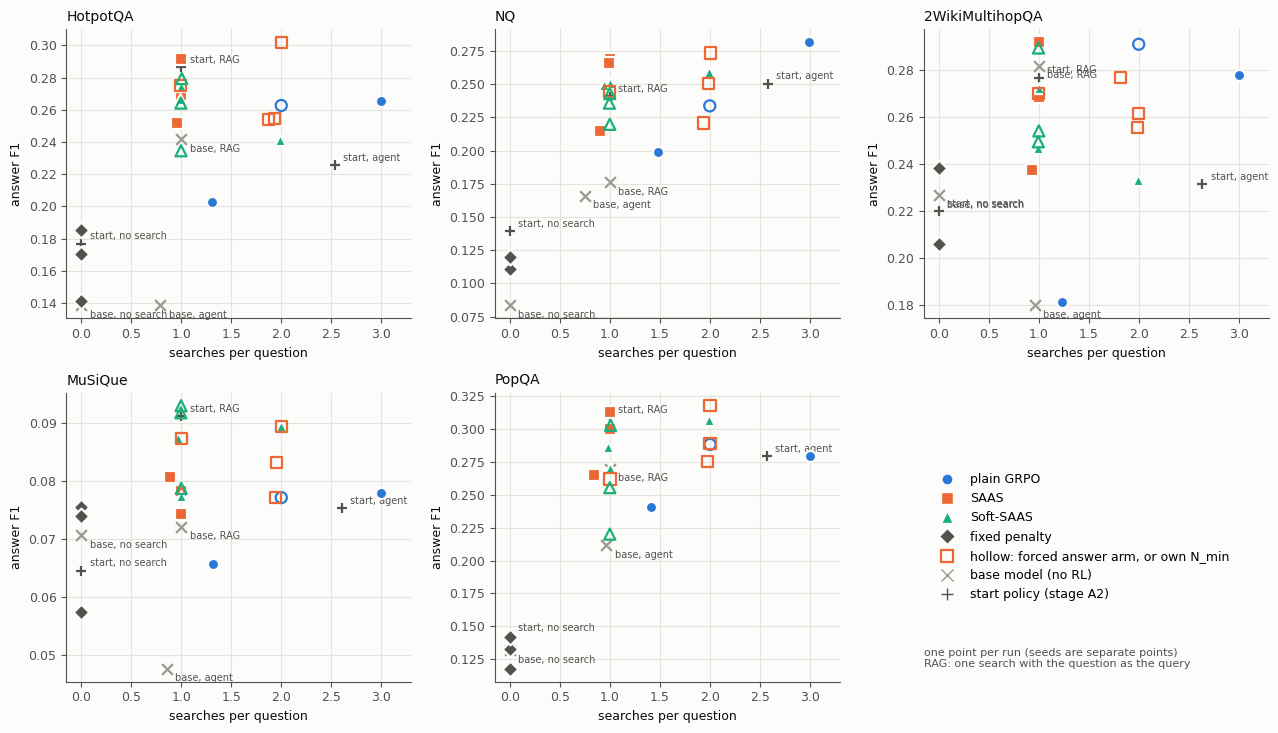

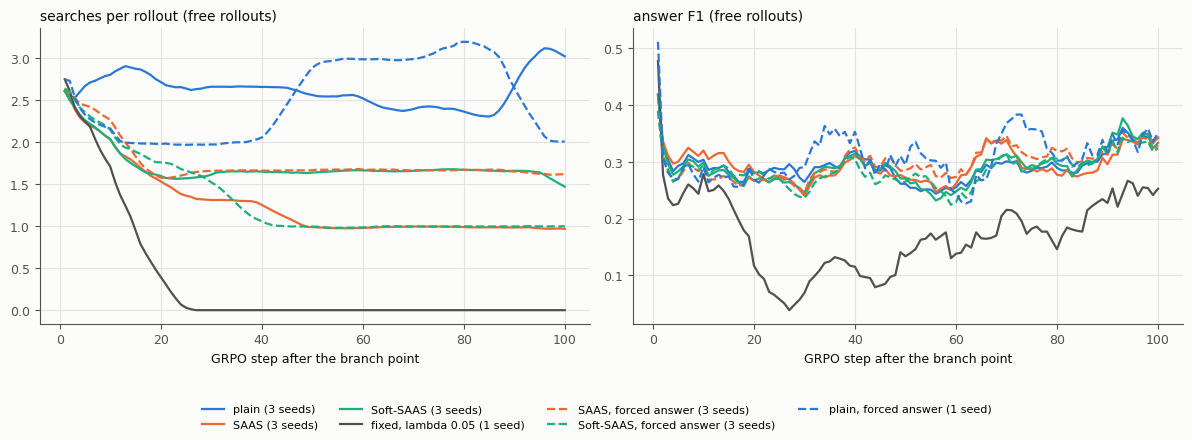

{"gpu":"NVIDIA L4","store":"drive","ood_data":{"2wiki":{"pool":12576,"n":1000,"with_sup_titles":1.0,"metadata_keys":["context","supporting_facts","type"],"example":{"id":"2wiki_dev_6","question":"Where was the father of \u0218tefan I. Neni\u021bescu born?","golds":["Galac","Gala\u0163i","Galati","Galatz","Gala\u021bi"],"sup_titles":["Ioan S. Neni\u021bescu","\u0218tefan I. Neni\u021bescu"]}},"musique":{"pool":2417,"n":500,"with_sup_titles":0.0,"metadata_keys":["answerable","question_decomposition"],"example":{"id":"musique_dev_0","question":"Who is the spouse of the Green performer?","golds":["Miquette Giraudy"],"sup_titles":[]}},"popqa":{"pool":14267,"n":500,"with_sup_titles":0.0,"metadata_keys":["o_aliases","o_pop","o_uri","o_wiki_title","obj","obj_id","prop","prop_id","s_aliases","s_pop","s_uri","s_wiki_title","subj","subj_id"],"example":{"id":"popqa_test_9","question":"What is \u00deorsteinn Bachmann's occupation?","golds":["actor","actress","actors","actresses"],"sup_titles":[]}}}

In [16]:
import collections
import random
import statistics

import matplotlib.pyplot as plt

from sot.analysis import failure_modes, load_jsonl, paired_bootstrap, qor, seed_averaged_paired, sor, summarize
from sot.scoring import knows

NEW = ["B_plain_s1", "B_plain_s2", "B_saas_fa_s0", "B_soft_fa_s0", "B_plain_fa_s0", "B_saas_own_s0", "B_saas_fa_s1", "B_soft_fa_s1", "B_saas_fa_s2", "B_soft_fa_s2"]
SETS = ["hotpotqa", "nq", "2wiki", "musique", "popqa"]
NAME = {"hotpotqa": "HotpotQA", "nq": "NQ", "2wiki": "2WikiMultihopQA", "musique": "MuSiQue", "popqa": "PopQA"}
UNITS_PER_HOUR = 5.4 if "A100" in GPU else 1.7  # L4


def r4(x, d=4):
    if isinstance(x, dict):
        return {k: r4(v, d) for k, v in x.items()}
    if isinstance(x, list):
        return [r4(v, d) for v in x]
    return round(x, d) if isinstance(x, float) else x


def rows_of(folder, task):
    """A policy's test rows: HotpotQA and NQ from outputs/<folder>/, the new sets from outputs/<folder>_ood/."""
    out = []
    for f in (folder, folder + "_ood"):
        if os.path.exists(f"{OUT}/{f}/{task}.jsonl"):
            out += load_jsonl(f"{OUT}/{f}/{task}.jsonl")
    return out


def finished(t):
    return os.path.exists(f"{RUN}{t}/done.json") and os.path.exists(f"{OUT}/{t}/agent.jsonl")


test_recs = {r["id"]: r for ds in SETS if os.path.exists(f"{DATA}/{ds}_test.jsonl")
             for r in load_jsonl(f"{DATA}/{ds}_test.jsonl")}
POLICIES = {"base_closed": ("base_0.5B", "no_search"), "base_rag": ("base_0.5B", "rag"), "base_agent": ("base_0.5B", "agent"),
            "start_closed": ("stageA2", "no_search"), "start_rag": ("stageA2", "rag"), "start_agent": ("stageA2", "agent")}
POLICIES.update({t: (t, "agent") for t in STAGE_B + NEW if finished(t)})
rows = {name: rows_of(folder, task) for name, (folder, task) in POLICIES.items()}
rows = {k: v for k, v in rows.items() if v}


def p_map(folder):
    """p(q) on the test sets: share of K closed book samples whose answer covers a gold answer."""
    path = f"{OUT}/{folder}/closed_test.jsonl"
    d = collections.defaultdict(list)
    for r in (load_jsonl(path) if os.path.exists(path) else []):
        d[r["id"]].append(knows(r["answer"], test_recs[r["id"]]["golds"]))
    return {k: statistics.mean(v) for k, v in d.items()}


P_BASE, P_START = p_map("base_0.5B_pq"), p_map("stageA2_pq")


def metrics(rs):
    """Per test set: EM, F1, searches (SC), format; QOR under the base model's and the start policy's p(q), with the
    search rate on the questions they could not answer; SOR; redundant searches; distinct queries."""
    out = {ds: {"em": m["em"], "f1": m["f1"], "sc": m["searches"], "format": m["format_ok"]}
           for ds, m in summarize(rs).items()}
    for name, pm in (("base", P_BASE), ("start", P_START)):  # how many questions count as known: see p_test
        for ds, q in qor(rs, pm).items():
            out[ds].update({f"qor_{name}": q["qor"], f"search_rate_rest_{name}": q["search_rate_rest"]})
            if name == "start":
                out[ds]["f1_known_start"] = q["f1_eligible"]
    for ds, s in sor(rs, test_recs).items():
        out[ds].update({"sor": s["sor"], "evidence_complete": s["complete"]})
    for ds, m in failure_modes(rs).items():
        out[ds].update({"repeat": m["repeat_query"], "distinct_queries": m["distinct_queries"],
                        "think_closed": m["think_closed"], "no_tag": m["stop"].get("no_tag", 0.0)})
    return out


def versus(a, b, keys=("f1", "n_search")):
    """b minus a on the same test questions, per set, with paired 95% intervals."""
    if a not in rows or b not in rows:
        return None
    A = {r["id"]: r for r in rows[a]}
    out = {}
    for ds in SETS:
        pairs = [(A[r["id"]], r) for r in rows[b] if r["dataset"] == ds and r["id"] in A]
        if pairs:
            out[ds] = {m: paired_bootstrap([x[m] for x, _ in pairs], [y[m] for _, y in pairs]) for m in keys}
    return out


def seeds(prefix):
    return [t for t in (f"{prefix}_s0", f"{prefix}_s1", f"{prefix}_s2") if t in rows]


def averaged(a_prefix, b_prefix):
    """b minus a with each question averaged over the seeds of each side first (seed 0 to 2 where they exist)."""
    sa, sb = seeds(a_prefix), seeds(b_prefix)
    if not sa or not sb:
        return None
    out = {"seeds": [len(sa), len(sb)]}
    for ds in SETS:
        A = [[r for r in rows[t] if r["dataset"] == ds] for t in sa]
        B_ = [[r for r in rows[t] if r["dataset"] == ds] for t in sb]
        if all(A) and all(B_):
            out[ds] = {m: seed_averaged_paired(A, B_, m) for m in ("f1", "n_search")}
    return out


def training(tag):
    path = f"{RUN}{tag}/log.jsonl"
    if not os.path.exists(path):
        return None
    steps = [s for s in map(json.loads, open(path)) if "reward" in s]
    sec = sorted(b["wall_s"] - a["wall_s"] for a, b in zip(steps, steps[1:]) if b["step"] == a["step"] + 1)
    keys = ("f1", "f1_forced_answer", "searches_mean", "n0_share", "n1_share", "n2plus_share", "repeat_share",
            "penalised_share", "forced_share", "zero_var_share", "format_ok", "entropy")
    return {"steps": len(steps), "finished": os.path.exists(f"{RUN}{tag}/done.json"),
            "sec_per_step": round(statistics.median(sec), 1) if sec else None,
            "blocks_of_25_steps": {k: [round(statistics.mean(s[k] for s in steps[i:i + 25] if k in s), 3)
                                       for i in range(0, len(steps), 25) if any(k in s for s in steps[i:i + 25])]
                                   for k in keys if any(k in s for s in steps)}}


policy = {name: metrics(rs) for name, rs in rows.items()}
soft_minus_saas = {f"s{k}": versus(f"B_saas_s{k}", f"B_soft_s{k}") for k in range(3)}
soft_minus_saas = {k: v for k, v in soft_minus_saas.items() if v}
success_rule = {}
for ds in ("hotpotqa", "2wiki", "musique"):  # the multi hop sets
    per = [v[ds] for v in soft_minus_saas.values() if ds in v]
    success_rule[ds] = {"seeds": len(per), "sc_within_0.1": all(abs(p["n_search"]["diff"]) <= 0.1 for p in per),
                        "f1_higher_outside_ci": all(p["f1"]["lo"] > 0 for p in per),
                        "f1_diff_by_seed": [p["f1"]["diff"] for p in per]}
    success_rule[ds]["met"] = len(per) == 3 and success_rule[ds]["sc_within_0.1"] and success_rule[ds]["f1_higher_outside_ci"]

comparisons = {
    "soft_minus_saas": soft_minus_saas,
    "soft_minus_saas_seed_avg": averaged("B_saas", "B_soft"),
    "minus_plain_same_seed": {t: versus(f"B_plain_s{t[-1]}", t) for t in rows
                              if t.startswith(("B_saas_s", "B_soft_s", "B_fixed")) and f"B_plain_s{t[-1]}" in rows},
    "saas_minus_plain_seed_avg": averaged("B_plain", "B_saas"),
    "soft_minus_plain_seed_avg": averaged("B_plain", "B_soft"),
    "minus_start_rag": {t: versus("start_rag", t, ("f1",)) for t in rows if t.startswith("B_") or t == "start_agent"},
    "minus_start_agent": {t: versus("start_agent", t, ("f1",)) for t in rows if t.startswith("B_")},
    "own_nmin_minus_saas": versus("B_saas_s0", "B_saas_own_s0"),
    "forced_minus_unforced": {f: versus(u, f) for f, u in (("B_saas_fa_s0", "B_saas_s0"), ("B_soft_fa_s0", "B_soft_s0"),
                                                           ("B_plain_fa_s0", "B_plain_s0")) if f in rows},
    "forced_minus_unforced_seed_avg": {"saas": averaged("B_saas", "B_saas_fa"), "soft": averaged("B_soft", "B_soft_fa")},
    "forced_soft_minus_saas_seed_avg": averaged("B_saas_fa", "B_soft_fa"),
    "forced_saas_minus_forced_plain": versus("B_plain_fa_s0", "B_saas_fa_s0"),
    "forced_soft_minus_forced_plain": versus("B_plain_fa_s0", "B_soft_fa_s0"),
}

# figures
os.makedirs(f"{OUT}/figures", exist_ok=True)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
FAMILY = {"plain": ("#2a78d6", "o"), "saas": ("#eb6834", "s"), "soft": ("#1baf7a", "^"), "fixed": (INK2, "D")}
plt.rcParams.update({"axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "figure.facecolor": SURF, "axes.facecolor": SURF, "font.size": 9})


def family(t):
    return next(f for f in FAMILY if t.startswith(f"B_{f}"))


fig, axes = plt.subplots(2, 3, figsize=(13, 7.4))
for ax, ds in zip(axes.flat, SETS):
    for name, (lab, mk) in {"base_closed": ("base, no search", "x"), "base_rag": ("base, RAG", "x"),
                            "base_agent": ("base, agent", "x"), "start_closed": ("start, no search", "+"),
                            "start_rag": ("start, RAG", "+"), "start_agent": ("start, agent", "+")}.items():
        m = policy.get(name, {}).get(ds)
        if m:
            ax.scatter(m["sc"], m["f1"], marker=mk, s=60, color=INK2 if name.startswith("start") else "#9a9890",
                       linewidths=1.6, zorder=3)
            ax.annotate(lab, (m["sc"], m["f1"]), textcoords="offset points", fontsize=7, color=INK2,
                        xytext=(6, 3) if name.startswith("start") else (6, -9))  # start labels above, base below
    for t in rows:
        if not t.startswith("B_") or ds not in policy[t]:
            continue
        col, mk = FAMILY[family(t)]
        hollow = "_fa_" in t or "_own_" in t
        ax.scatter(policy[t][ds]["sc"], policy[t][ds]["f1"], marker=mk, s=64, zorder=4, linewidths=1.6,
                   facecolors="none" if hollow else col, edgecolors=col if hollow else SURF)
    ax.set_title(NAME[ds], color=INK, fontsize=10, loc="left")
    ax.set_xlim(-0.15, 3.3)
    ax.set_xlabel("searches per question")
    ax.set_ylabel("answer F1")
leg = axes.flat[5]
leg.axis("off")
handles = [plt.Line2D([], [], marker=mk, ls="", color=col, markersize=8, markeredgecolor=SURF, label=lab)
           for lab, (col, mk) in (("plain GRPO", FAMILY["plain"]), ("SAAS", FAMILY["saas"]), ("Soft-SAAS", FAMILY["soft"]),
                                  ("fixed penalty", FAMILY["fixed"]))]
handles += [plt.Line2D([], [], marker="s", ls="", markerfacecolor="none", markeredgecolor=FAMILY["saas"][0],
                       markersize=8, markeredgewidth=1.6, label="hollow: forced answer arm, or own N_min"),
            plt.Line2D([], [], marker="x", ls="", color="#9a9890", markersize=8, label="base model (no RL)"),
            plt.Line2D([], [], marker="+", ls="", color=INK2, markersize=9, label="start policy (stage A2)")]
leg.legend(handles=handles, loc="center left", frameon=False, fontsize=9)
leg.text(0.0, 0.05, "one point per run (seeds are separate points)\nRAG: one search with the question as the query",
         fontsize=8, color=INK2, transform=leg.transAxes)
fig.tight_layout()
fig.savefig(f"{OUT}/figures/frontier.png", dpi=200)
plt.show()


def curve(tags, key):
    logs = [[s for s in map(json.loads, open(f"{RUN}{t}/log.jsonl")) if key in s] for t in tags
            if os.path.exists(f"{RUN}{t}/log.jsonl")]
    n = min((len(x) for x in logs), default=0)
    if not n:
        return [], []
    ys = [statistics.mean(x[i][key] for x in logs) for i in range(n)]
    sm = [statistics.mean(ys[max(0, i - 9):i + 1]) for i in range(n)]  # 10 step running mean
    return [logs[0][i]["step"] for i in range(n)], sm


fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, key, lab in ((axes[0], "searches_mean", "searches per rollout (free rollouts)"), (axes[1], "f1", "answer F1 (free rollouts)")):
    for name, prefix, style in (("plain", "B_plain", "-"), ("SAAS", "B_saas", "-"), ("Soft-SAAS", "B_soft", "-"),
                                ("fixed, lambda 0.05", "B_fixed05", "-"), ("SAAS, forced answer", "B_saas_fa", "--"),
                                ("Soft-SAAS, forced answer", "B_soft_fa", "--"), ("plain, forced answer", "B_plain_fa", "--")):
        tags = [t for t in (f"{prefix}_s0", f"{prefix}_s1", f"{prefix}_s2") if os.path.exists(f"{RUN}{t}/log.jsonl")]
        xs, ys = curve(tags, key)
        if xs:
            col = FAMILY[family(prefix + "_")][0]
            ax.plot(xs, ys, style, color=col, lw=1.6, label=f"{name} ({len(tags)} seed{'s' * (len(tags) > 1)})")
    ax.set_xlabel("GRPO step after the branch point")
    ax.set_title(lab, color=INK, fontsize=10, loc="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.13, 1, 1))
fig.savefig(f"{OUT}/figures/stageB_training.png", dpi=200)
plt.show()

summary = r4({"gpu": GPU, "store": STORE, "ood_data": OOD_REPORT, "policies_evaluated": sorted(rows),
              "p_test": {name: {ds: {"known": sum(pm[i] >= 0.5 for i in pm if test_recs[i]["dataset"] == ds),
                                     "n": sum(test_recs[i]["dataset"] == ds for i in pm)} for ds in SETS}
                         for name, pm in (("base", P_BASE), ("start", P_START))},
              "policy": policy, "success_rule": success_rule, "comparisons": comparisons,
              "new_runs_training": {t: training(t) for t in NEW if training(t)},
              "units_used_estimate": round(sum((tr["steps"] * (tr["sec_per_step"] or 0)) for t in NEW
                                               for tr in [training(t)] if tr) / 3600 * UNITS_PER_HOUR, 1),
              "free_gb": round(shutil.disk_usage(PROJECT).free / 1e9)})
with open(f"{OUT}/final_summary.json", "w") as f:
    json.dump(summary, f, indent=1)
push("outputs")
push_runs([t for t in NEW if t in rows])
print(json.dumps(r4(summary, 3), separators=(",", ":")))

# 20 out of domain questions under the main policies
SHOW = [t for t in ("start_agent", "B_plain_s0", "B_saas_s0", "B_soft_s0", "B_saas_fa_s0", "B_soft_fa_s0") if t in rows]
by_id = {t: {r["id"]: r for r in rows[t]} for t in SHOW}
pool = [i for i in by_id["start_agent"] if test_recs[i]["dataset"] in ("2wiki", "musique")] if "start_agent" in by_id else []
print("\n20 out of domain questions (set | question | gold | start p(q) | per policy: queries, answer, F1):")
for qid in random.Random(0).sample(sorted(pool), min(20, len(pool))):
    q = test_recs[qid]
    cell = {t.replace("B_", "").replace("_s0", "").replace("_agent", ""): [[s["query"][:55] for s in by_id[t][qid]["searches"]],
                                                                            (by_id[t][qid]["answer"] or "")[:40], round(by_id[t][qid]["f1"], 2)]
            for t in SHOW if qid in by_id[t]}
    print(json.dumps([q["dataset"][:4], q["question"][:100], q["golds"][0][:40], round(P_START.get(qid, -1), 2), cell],
                     ensure_ascii=False))

In [ ]:
from google.colab import runtime
runtime.unassign()